# Predicting Online Purchases — model comparison, single-winner audit and final refit

This analysis compares four taught baselines with three evidence-motivated revisions for predicting observed purchase sessions. It uses a fixed stratified training/holdout split; model comparison, selection and policy illustrations below use training out-of-fold predictions. The held-out partition is used only for the final frozen-winner audit, followed by an exact all-data refit. Results describe retrospective prediction, not voucher effects or verified real-time availability.

**Research question.** How well can session variables rank purchase sessions, and how do fixed voucher assumptions change illustrative policy arithmetic? Historical session Revenue is the outcome; these records do not identify voucher conversion effects.

## 0. Fixed protocol and purpose

**Purpose.** Establish evaluation and policy assumptions before interpreting model comparisons. **Method.** Retain all source rows; split once into stratified 80% training and 20% holdout with seed 42; use identical shuffled five-fold stratified training folds. Training EDA, CV, candidate selection and threshold-reference comparisons use training rows only. The fixed-policy q illustration uses training OOF predictions and later reuses only the single frozen held-out vector after its audit. **Implication.** ROC-AUC is the primary ranking metric and average precision is supporting evidence at a 15.5% purchase rate. A prior overlapping 75/25 analysis examined this dataset, so the reserved holdout is not historically untouched. No held-out predictor or outcome summaries are used in training decisions.

In [1]:
from pathlib import Path
import hashlib, json, warnings, platform, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt, scipy, sklearn
from scipy import stats
from scipy.special import logsumexp
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.exceptions import ConvergenceWarning
import statsmodels.api as sm
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss, roc_curve, confusion_matrix

RUN_START=time.perf_counter()
SEED=42; TEST_FRAC=.20; K=5
TARGET='Revenue'
NUMERIC_ALL=['Administrative','Administrative_Duration','Informational','Informational_Duration',
 'ProductRelated','ProductRelated_Duration','BounceRates','ExitRates','PageValues','SpecialDay']
CAT=['Month','OperatingSystems','Browser','Region','TrafficType','VisitorType']
ACTIVITY=['Administrative','Administrative_Duration','Informational','Informational_Duration','ProductRelated','ProductRelated_Duration']
NUMERIC_SAFE=[x for x in NUMERIC_ALL if x!='PageValues']
ALL=NUMERIC_ALL+CAT+['Weekend']; SAFE=NUMERIC_SAFE+CAT+['Weekend']
EXPECTED=set(ALL+[TARGET])
root_candidates=[Path('data/uci_468.csv'),Path('../data/uci_468.csv')]
data_path=next((p for p in root_candidates if p.is_file()),None)
if data_path is None: raise FileNotFoundError('Run from repository root or a direct child directory; expected data/uci_468.csv')
ROOT=data_path.parent.parent if data_path.parent.name=='data' else data_path.parent.parent
ARTIFACTS=ROOT/'artifacts'; ARTIFACTS.mkdir(exist_ok=True)
WORK=ROOT/'work'; WORK.mkdir(exist_ok=True)
PROGRESS_LOG=WORK/'baseline_progress.jsonl'; PROGRESS_LOG.write_text('')
def mark_progress(candidate,fold,event,**details):
    record={'candidate':candidate,'fold':fold,'event':event,'elapsed_seconds':round(time.perf_counter()-RUN_START,3),**details}
    with PROGRESS_LOG.open('a') as f: f.write(json.dumps(record,default=str)+'\n')
print(f'Python {platform.python_version()} | pandas {pd.__version__} | NumPy {np.__version__} | SciPy {scipy.__version__} | scikit-learn {sklearn.__version__}')
print('Operational selection uses mean five-fold training ROC-AUC; AP and fold variation are supporting evidence. Policy illustrations use only winner training OOF predictions.')

Fontconfig error: No writable cache directories


Python 3.12.14 | pandas 3.0.6 | NumPy 2.5.4 | SciPy 1.18.1 | scikit-learn 1.9.1
Operational selection uses mean five-fold training ROC-AUC; AP and fold variation are supporting evidence. Policy illustrations use only winner training OOF predictions.


## 1. Data quality, split and row provenance (A1)

**Purpose.** Verify that the source is complete and internally consistent, and establish exact reproducible row membership before examining predictors. **Method.** Check shape, columns, types, numeric finiteness, missing and blank nominal values, duplicates and class balance; retain all sessions. Split row IDs once, store them, sort training rows by original file order, and materialise shared five-fold row-ID mappings. **Implication.** Identical records are not evidence of identical visitors; duplicates remain. All predictor summaries below use the 80% training partition.

In [2]:
raw=pd.read_csv(data_path); raw.insert(0,'_row_id',np.arange(len(raw),dtype=int))
source_hash=hashlib.sha256(data_path.read_bytes()).hexdigest()
if raw.shape!=(12330,19): raise ValueError(f'Expected 12,330 rows and 18 source columns, found {raw.shape}')
if set(raw.columns)-{'_row_id'} != EXPECTED: raise ValueError(f'Unexpected source columns: {sorted((set(raw.columns)-{"_row_id"}) ^ EXPECTED)}')
if raw[TARGET].isna().any() or not set(raw[TARGET].unique()).issubset({0,1,False,True}): raise ValueError('Revenue must be complete binary 0/1')
raw[TARGET]=raw[TARGET].astype(int)
if raw[NUMERIC_ALL].isna().any().any() or not np.isfinite(raw[NUMERIC_ALL].to_numpy(float)).all(): raise ValueError('Numeric source predictors must be complete and finite')
blank=raw[CAT].astype('string').apply(lambda s:s.str.strip().eq('').sum())
missing=raw.drop(columns='_row_id').isna().sum()
if missing.any() or blank.any(): raise ValueError('Unexpected missing values or blank nominal markers; inspect source before modelling')
if raw['Weekend'].isna().any() or not set(raw['Weekend'].unique()).issubset({0,1,False,True}): raise ValueError('Weekend must be complete binary 0/1')
quality=pd.DataFrame({'dtype':raw.drop(columns='_row_id').dtypes.astype(str),'missing':missing,
                      'blank nominal':blank.reindex(missing.index,fill_value=0),'unique':raw.drop(columns='_row_id').nunique()})
print('Source shape (rows, columns):',(len(raw),len(raw.columns)-1),'SHA-256:',source_hash)
print('Duplicate excess / unique full rows:',int(raw.duplicated(subset=raw.columns.drop('_row_id')).sum()),'/',raw.drop(columns='_row_id').drop_duplicates().shape[0])
display(quality)
display(raw[TARGET].value_counts().sort_index().rename_axis(TARGET).to_frame('sessions').assign(share=lambda d:d.sessions/len(raw)))
dup=raw.loc[raw.duplicated(subset=raw.columns.drop('_row_id'),keep='first')]
print(f'Excess duplicates: {len(dup)}; duplicate outcomes:',dup[TARGET].value_counts().sort_index().to_dict())
display(pd.DataFrame({'duplicate median activity':dup[ACTIVITY].median(),'duplicate zero share':dup[ACTIVITY].eq(0).mean()}))
print('Reverified duplicate description: duplicate rows are nonbuyers with low activity summaries; all rows remain. This does not identify unique people or repeated sessions.')

train_ids,test_ids=train_test_split(raw['_row_id'].to_numpy(),test_size=TEST_FRAC,
    stratify=raw[TARGET].to_numpy(),random_state=SEED)
train_ids=np.sort(train_ids); test_ids=np.sort(test_ids)
pd.DataFrame({'row_id':train_ids,'partition':'train'}).to_csv(ARTIFACTS/'train_row_ids.csv',index=False)
pd.DataFrame({'row_id':test_ids,'partition':'test'}).to_csv(ARTIFACTS/'test_row_ids.csv',index=False)
train=raw.set_index('_row_id').loc[train_ids].copy()
y_train=train.pop(TARGET).astype(int)
X_train=train[ALL].copy()
X_train[CAT]=X_train[CAT].astype('string')
X_train['Weekend']=X_train['Weekend'].astype(int)
del raw,dup
cv=StratifiedKFold(n_splits=K,shuffle=True,random_state=SEED)
FOLD_INDICES=list(cv.split(np.zeros(len(y_train)),y_train))
fold_map=[]
for fold,(fit_idx,val_idx) in enumerate(FOLD_INDICES,1):
    fold_map += [{'row_id':int(X_train.index[i]),'fold':fold,'role':'fit'} for i in fit_idx]
    fold_map += [{'row_id':int(X_train.index[i]),'fold':fold,'role':'validation'} for i in val_idx]
pd.DataFrame(fold_map).to_csv(ARTIFACTS/'cv_fold_row_ids.csv',index=False)
print(f'Training={len(X_train):,}; holdout IDs recorded={len(test_ids):,}; purchases={y_train.sum():,} ({y_train.mean():.2%}).')
print('Shared validation fold sizes:',[len(v) for _,v in FOLD_INDICES],'; row-ID order is sorted original CSV order.')
print('The holdout is reserved: no predictor/outcome summaries, fitted transforms, or evaluation are performed on those rows.')

Source shape (rows, columns): (12330, 18) SHA-256: b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9
Duplicate excess / unique full rows: 125 / 12205


,dtype,missing,blank nominal,unique
Administrative,int64,0,0,27
Administrative_Duration,float64,0,0,3335
Informational,int64,0,0,17
Informational_Duration,float64,0,0,1258
ProductRelated,int64,0,0,311
ProductRelated_Duration,float64,0,0,9551
BounceRates,float64,0,0,1872
ExitRates,float64,0,0,4777
PageValues,float64,0,0,2704
SpecialDay,float64,0,0,6


,sessions,share
Revenue,,
0,10422,0.845255
1,1908,0.154745


Excess duplicates: 125; duplicate outcomes: {0: 125}


,duplicate median activity,duplicate zero share
Administrative,0.0,1.0
Administrative_Duration,0.0,1.0
Informational,0.0,1.0
Informational_Duration,0.0,1.0
ProductRelated,1.0,0.0
ProductRelated_Duration,0.0,1.0


Reverified duplicate description: duplicate rows are nonbuyers with low activity summaries; all rows remain. This does not identify unique people or repeated sessions.


Training=9,864; holdout IDs recorded=2,466; purchases=1,526 (15.47%).
Shared validation fold sizes: [1973, 1973, 1973, 1973, 1972] ; row-ID order is sorted original CSV order.
The holdout is reserved: no predictor/outcome summaries, fitted transforms, or evaluation are performed on those rows.


## 2. Numerical training EDA (A2)

**Purpose.** Identify skewed, zero-heavy session measures that may challenge Gaussian likelihoods or suggest alternative representations. **Method.** Summarise training medians, zero shares and skewness; plot selected raw distributions with log-scaled counts. **Implication.** EDA generates fixed hypotheses for later recipe review; it does not select transforms by model performance.

,median,zero share,skew,buyer median,nonbuyer median
Administrative,1.000,0.467,1.967,2.000,0.000
Administrative_Duration,8.000,0.477,5.679,53.125,0.000
Informational,0.000,0.785,4.142,0.000,0.000
Informational_Duration,0.000,0.805,7.702,0.000,0.000
ProductRelated,18.000,0.003,4.372,29.000,16.000
ProductRelated_Duration,600.537,0.062,8.009,1120.850,511.333
BounceRates,0.003,0.448,2.924,0.000,0.004
ExitRates,0.025,0.006,2.130,0.016,0.029
PageValues,0.000,0.778,6.187,17.323,0.000
SpecialDay,0.000,0.897,3.261,0.000,0.000


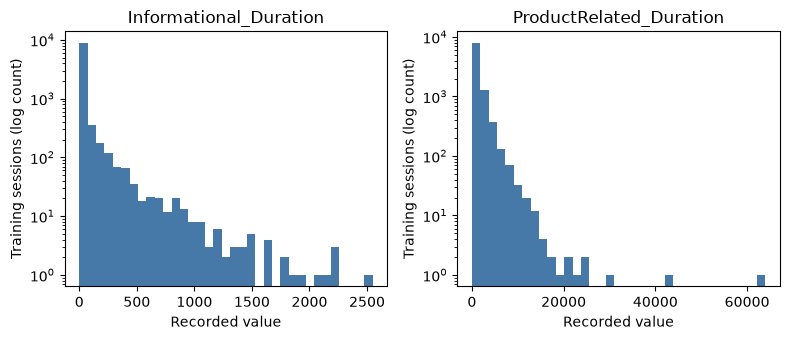

Five of six activity fields have skew above 2; Administrative count is just below at 1.97.
Informational count/duration are zero in 78.5%/80.5% of training sessions, with buyer rates 13.3%/13.5% at zero versus 23.4%/23.6% when positive.
Implication: the long tails motivate reviewing the preapproved activity log1p form; only informational count and duration meet the training ≥50% zero-share rule for fold-fitted presence indicators. No model comparison is made here.


In [3]:
Xtr=X_train; ytr=y_train
num_summary=pd.DataFrame({'median':Xtr[NUMERIC_ALL].median(),'zero share':Xtr[NUMERIC_ALL].eq(0).mean(),
                          'skew':Xtr[NUMERIC_ALL].skew(),'buyer median':Xtr.loc[ytr.eq(1),NUMERIC_ALL].median(),
                          'nonbuyer median':Xtr.loc[ytr.eq(0),NUMERIC_ALL].median()})
display(num_summary.round(3))
fig,axes=plt.subplots(1,2,figsize=(8,3.5))
for ax,col in zip(axes.flat,['Informational_Duration','ProductRelated_Duration']):
    ax.hist(Xtr[col],bins=35,log=True,color='#4779a8'); ax.set(title=col,xlabel='Recorded value',ylabel='Training sessions (log count)')
plt.tight_layout(); plt.show()
long_tail=num_summary.loc[ACTIVITY,'skew']
print('Five of six activity fields have skew above 2; Administrative count is just below at {:.2f}.'.format(long_tail['Administrative']))
print('Informational count/duration are zero in {:.1%}/{:.1%} of training sessions, with buyer rates {:.1%}/{:.1%} at zero versus {:.1%}/{:.1%} when positive.'.format(
 num_summary.loc['Informational','zero share'],num_summary.loc['Informational_Duration','zero share'],
 ytr[Xtr.Informational.eq(0)].mean(),ytr[Xtr.Informational_Duration.eq(0)].mean(),
 ytr[Xtr.Informational.gt(0)].mean(),ytr[Xtr.Informational_Duration.gt(0)].mean()))
print('Implication: the long tails motivate reviewing the preapproved activity log1p form; only informational count and duration meet the training ≥50% zero-share rule for fold-fitted presence indicators. No model comparison is made here.')

## 3. Categorical training EDA (A3)

**Purpose.** Check whether purchase rates vary across nominal groups and whether sparse levels make those rates unstable. **Method.** Display level counts and buyer rates for each nominal feature and selected VisitorType×Month support. **Implication.** Treat nominal values as unranked categories; sparse rates do not justify arbitrary pooling or interaction terms.

In [4]:
cat_summary=[]
for col in CAT:
    tab=Xtr.assign(Revenue=ytr).groupby(col,observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),buyer_rate=('Revenue','mean'))
    cat_summary.append({'feature':col,'levels':len(tab),'small levels <50':int((tab.sessions<50).sum()),
      'small-level sessions':int(tab.loc[tab.sessions<50,'sessions'].sum()),
      'buyer-rate range':f"{tab.buyer_rate.min():.1%}–{tab.buyer_rate.max():.1%}"})
display(pd.DataFrame(cat_summary).set_index('feature'))
for col in ['Month','VisitorType']:
    tab=Xtr.assign(Revenue=ytr).groupby(col,observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),buyer_rate=('Revenue','mean')).sort_values('sessions',ascending=False)
    print(f'Training group counts and observed buyer rates: {col}')
    display(tab.round(3))
rare=[]
for col in ['TrafficType','Browser','Region']:
    tab=Xtr.assign(Revenue=ytr).groupby(col,observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),buyer_rate=('Revenue','mean'))
    small=tab[tab.sessions<50]
    rare.append({'feature':col,'levels below n=50':len(small),'total levels':len(tab),
                 'rare-cell rate range':f"{small.buyer_rate.min():.1%}–{small.buyer_rate.max():.1%}" if len(small) else 'none'})
print('Rare-category evidence (summary only; detailed training-only investigation is in supplementary/training_eda.ipynb):')
display(pd.DataFrame(rare).set_index('feature'))
vtm=Xtr.assign(Revenue=ytr).groupby(['VisitorType','Month'],observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),buyer_rate=('Revenue','mean')).reset_index()
print(f"VisitorType × Month has {int((vtm.sessions<50).sum())} cells below n=50 out of {len(vtm)} observed; the cross-cell display/rates are retained in the supplementary EDA only.")
special=Xtr.assign(Revenue=ytr).groupby('SpecialDay',observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),buyer_rate=('Revenue','mean'))
display(special.round(4))
print('SpecialDay zero/positive purchase rates: {:.1%}/{:.1%}; positive score rates are nonmonotone. Keep numeric baseline; presence is considered only for reviewed NB revision.'.format(ytr[Xtr.SpecialDay.eq(0)].mean(),ytr[Xtr.SpecialDay.gt(0)].mean()))
print('Implication: nominal predictors require categorical encoding; sparse level/cross-cell rates are uncertain and do not motivate arbitrary pooling or an interaction.')

,levels,small levels <50,small-level sessions,buyer-rate range
feature,,,,
Month,10,0,0,1.4%–24.8%
OperatingSystems,8,3,26,10.6%–25.0%
Browser,13,4,49,0.0%–42.9%
Region,9,0,0,14.2%–17.0%
TrafficType,20,9,140,0.0%–33.3%
VisitorType,3,0,0,14.0%–24.7%


Training group counts and observed buyer rates: Month


,sessions,buyers,buyer_rate
Month,,,
May,2703,292,0.108
Nov,2360,586,0.248
Mar,1538,159,0.103
Dec,1391,184,0.132
Oct,444,98,0.221
Sep,368,75,0.204
Jul,344,46,0.134
Aug,342,61,0.178
June,228,23,0.101


Training group counts and observed buyer rates: VisitorType


,sessions,buyers,buyer_rate
VisitorType,,,
Returning_Visitor,8443,1180,0.140
New_Visitor,1347,333,0.247
Other,74,13,0.176


Rare-category evidence (summary only; detailed training-only investigation is in supplementary/training_eda.ipynb):


,levels below n=50,total levels,rare-cell rate range
feature,,,
TrafficType,9,20,0.0%–33.3%
Browser,4,13,0.0%–42.9%
Region,0,9,none


VisitorType × Month has 4 cells below n=50 out of 22 observed; the cross-cell display/rates are retained in the supplementary EDA only.


,sessions,buyers,buyer_rate
SpecialDay,,,
0.0,8850,1466,0.1656
0.2,142,13,0.0915
0.4,189,9,0.0476
0.6,286,26,0.0909
0.8,271,6,0.0221
1.0,126,6,0.0476


SpecialDay zero/positive purchase rates: 16.6%/5.9%; positive score rates are nonmonotone. Keep numeric baseline; presence is considered only for reviewed NB revision.
Implication: nominal predictors require categorical encoding; sparse level/cross-cell rates are uncertain and do not motivate arbitrary pooling or an interaction.


## 4. Relationships and assumption checks (A4)

**Purpose.** Identify dependence and shape features that strain model assumptions without treating marginal diagnostics as formal tests. **Method.** Compare selected numeric correlations within each class, inspect representative class-specific tails and tie-safe marginal empirical logits. **Implication.** Dependence challenges Naive Bayes conditional independence. LDA permits correlated predictors; differing selected correlations can suggest covariance heterogeneity, while long tails and mixed inputs challenge its Gaussian ideal. None of these summaries proves unequal covariance or conditional logit nonlinearity.

The Q–Q panels compare observed class-conditional quantiles: left, ProductRelated_Duration; right, Informational_Duration. Colours identify observed non-buyers and buyers.


class 0: top absolute numeric correlations
BounceRates    ExitRates                                                  0.914923
ProductRelated ProductRelated_Duration                                    0.838882
Informational  Informational_Duration                                     0.632216
Administrative Administrative_Duration                                    0.585541
               ProductRelated                                             0.433914

class 1: top absolute numeric correlations
ProductRelated ProductRelated_Duration                                    0.895908
BounceRates    ExitRates                                                  0.723380
Informational  Informational_Duration                                     0.633768
Administrative Administrative_Duration                                    0.588880
               ProductRelated                                             0.404739

BounceRates/ExitRates correlations are 0.915 for nonbuyers and 0.723 for buyers; ProductRelated/ProductRelated_Duration are 0.839 and 0.896. These selected differences do not establish unequal full covariance matrices.


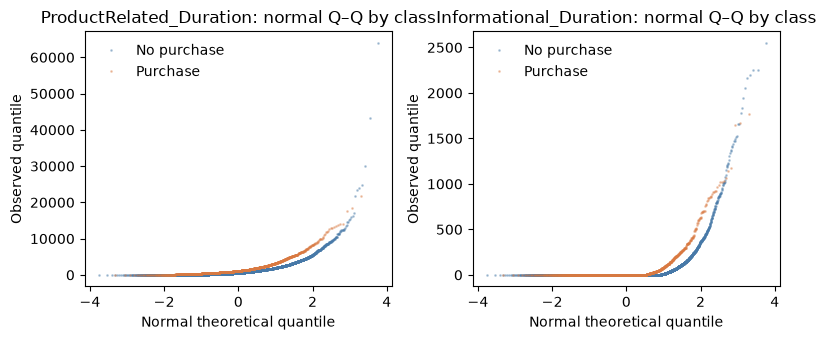

Marginal binned empirical logit (Informational_Duration; one zero group, positive ties preserved):


,bin,n,mean_x,buyers,rate,empirical_logit
8,zero,7938,0.0000,1071,0.1349,-1.8577
0,"(0.999, 14.0]",251,8.4271,48,0.1912,-1.4341
2,"(14.0, 28.25]",231,20.5510,58,0.2511,-1.0872
4,"(28.25, 47.5]",241,36.9795,58,0.2407,-1.1432
6,"(47.5, 75.583]",240,60.5977,41,0.1708,-1.5701
7,"(75.583, 121.0]",242,98.4897,55,0.2273,-1.2174
1,"(121.0, 201.3]",239,155.9662,56,0.2343,-1.1780
3,"(201.3, 378.021]",241,273.7505,74,0.3071,-0.8102
5,"(378.021, 2549.375]",241,762.6389,65,0.2697,-0.9913


Marginal binned empirical logit (ProductRelated_Duration; one zero group, positive ties preserved):


,bin,n,mean_x,buyers,rate,empirical_logit
8,zero,612,0.0000,8,0.0131,-4.2643
0,"(0.499, 105.344]",1157,52.2660,58,0.0501,-2.9336
2,"(105.344, 241.0]",1157,169.8017,68,0.0588,-2.7666
4,"(241.0, 428.038]",1156,327.7485,141,0.1220,-1.9708
6,"(428.038, 673.017]",1156,544.9692,200,0.1730,-1.5625
7,"(673.017, 1029.532]",1156,833.9943,245,0.2119,-1.3118
1,"(1029.532, 1564.04]",1157,1270.9825,248,0.2143,-1.2975
3,"(1564.04, 2593.783]",1156,2003.6607,238,0.2059,-1.3484
5,"(2593.783, 63973.522]",1157,4915.6784,320,0.2766,-0.9605


Marginal binned empirical logit (BounceRates; one zero group, positive ties preserved):


,bin,n,mean_x,buyers,rate,empirical_logit
8,zero,4423,0.0000,848,0.1917,-1.4384
0,"(-0.0009273, 0.00385]",689,0.0023,166,0.2409,-1.1455
1,"(0.00385, 0.00656]",672,0.0051,152,0.2262,-1.2276
2,"(0.00656, 0.01]",706,0.0082,133,0.1884,-1.4577
3,"(0.01, 0.0148]",659,0.0124,95,0.1442,-1.7768
4,"(0.0148, 0.0222]",706,0.0185,70,0.0992,-2.2004
5,"(0.0222, 0.0389]",649,0.0296,38,0.0586,-2.7653
6,"(0.0389, 0.1]",697,0.0619,21,0.0301,-3.4489
7,"(0.1, 0.2]",663,0.1909,3,0.0045,-5.2402


These marginal plots/tables generate hypotheses only; they do not establish conditional logit linearity or validate Gaussian assumptions.


In [5]:
NUM_SAFE=[c for c in NUMERIC_ALL if c!='PageValues']+['Weekend']
for cls in [0,1]:
    corr=Xtr.loc[ytr.eq(cls),NUM_SAFE].corr().abs()
    pairs=corr.where(np.triu(np.ones(corr.shape),k=1).astype(bool)).stack().sort_values(ascending=False).head(5)
    display(pairs.rename(f'class {cls}: top absolute numeric correlations').to_frame())
print('BounceRates/ExitRates correlations are {:.3f} for nonbuyers and {:.3f} for buyers; ProductRelated/ProductRelated_Duration are {:.3f} and {:.3f}. These selected differences do not establish unequal full covariance matrices.'.format(
 Xtr.loc[ytr.eq(0),['BounceRates','ExitRates']].corr().iloc[0,1],Xtr.loc[ytr.eq(1),['BounceRates','ExitRates']].corr().iloc[0,1],
 Xtr.loc[ytr.eq(0),['ProductRelated','ProductRelated_Duration']].corr().iloc[0,1],Xtr.loc[ytr.eq(1),['ProductRelated','ProductRelated_Duration']].corr().iloc[0,1]))
fig,axes=plt.subplots(1,2,figsize=(8,3.5))
for ax,col in zip(axes,['ProductRelated_Duration','Informational_Duration']):
    for cls,label,color in [(0,'No purchase','#4779a8'),(1,'Purchase','#d97941')]:
        vals=Xtr.loc[ytr.eq(cls),col].to_numpy()
        (osm,osr),_=stats.probplot(vals,dist='norm',fit=True)
        ax.plot(osm,osr,'.',ms=2,alpha=.35,label=label,color=color)
    ax.set(title=f'{col}: normal Q–Q by class',xlabel='Normal theoretical quantile',ylabel='Observed quantile'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

def marginal_elogit(col, bins=8):
    z=pd.DataFrame({'x':Xtr[col],'buyer':ytr}); z['bin']='zero'; positive=z.x.gt(0)
    if positive.any(): z.loc[positive,'bin']=pd.qcut(z.loc[positive,'x'],bins,duplicates='drop').astype(str)
    out=z.groupby('bin',observed=True).agg(n=('buyer','size'),mean_x=('x','mean'),buyers=('buyer','sum'),rate=('buyer','mean')).reset_index()
    out['empirical_logit']=np.log((out.buyers+.5)/(out.n-out.buyers+.5))
    return out.sort_values('mean_x')
for col in ['Informational_Duration','ProductRelated_Duration','BounceRates']:
    print(f'Marginal binned empirical logit ({col}; one zero group, positive ties preserved):')
    display(marginal_elogit(col).round(4))
print('These marginal plots/tables generate hypotheses only; they do not establish conditional logit linearity or validate Gaussian assumptions.')

In [6]:
class BinaryMagnitude(BaseEstimator,TransformerMixin):
    def fit(self,X,y=None): return self
    def transform(self,X): return (np.asarray(X,dtype=float)>0).astype(float)

def make_preprocessor(columns, family):
    nums=[x for x in NUMERIC_ALL if x in columns]
    cats=[x for x in CAT if x in columns]
    if family=='BernoulliNB': num_transform=BinaryMagnitude()
    else: num_transform='passthrough'
    drop='first' if family in ['Logit','LDA'] else None
    return ColumnTransformer([('numeric',num_transform,nums),
      ('categorical',OneHotEncoder(handle_unknown='ignore',drop=drop,sparse_output=False),cats),
      ('weekend','passthrough',['Weekend'])],remainder='drop',sparse_threshold=0.0,verbose_feature_names_out=False)

def make_estimator(family):
    if family=='Logit': return LogisticRegression(C=np.inf,solver='newton-cg',tol=1e-8,max_iter=2000)
    if family=='GaussianNB': return GaussianNB()
    if family=='BernoulliNB': return BernoulliNB(binarize=None)
    if family=='LDA': return LinearDiscriminantAnalysis(solver='svd')
    raise ValueError(family)

def make_pipeline(columns,family,estimator=None):
    return Pipeline([('pre',make_preprocessor(columns,family)),('clf',clone(estimator) if estimator is not None else make_estimator(family))])

CONFIGS={
 'Logit':{'family':'Logit','columns':ALL},
 'GaussianNB':{'family':'GaussianNB','columns':ALL},
 'BernoulliNB':{'family':'BernoulliNB','columns':ALL},
 'LDA':{'family':'LDA','columns':ALL}}

def pure_category_levels(X,y,cats):
    result=[]
    for col in cats:
        tab=pd.DataFrame({'level':X[col].astype(str).to_numpy(),'y':np.asarray(y)}).groupby('level').y.agg(['size','sum'])
        pure=tab[(tab['sum']==0)|(tab['sum']==tab['size'])]
        for level,r in pure.iterrows(): result.append(f'{col}={level}:n{int(r["size"])}:y{int(r["sum"])}')
    return result

def design_diagnostics(pre,Xfit):
    Z=np.asarray(pre.transform(Xfit),dtype=float)
    rank=int(np.linalg.matrix_rank(Z)); p=Z.shape[1]
    std=Z.std(axis=0); keep=std>1e-12
    Zn=(Z[:,keep]-Z[:,keep].mean(axis=0))/std[keep] if keep.any() else np.empty((len(Z),0))
    cond=float(np.linalg.cond(np.column_stack([np.ones(len(Z)),Zn]))) if Zn.shape[1] else np.nan
    return Z,rank,p,cond

def positive_probability(est,Z):
    classes=np.asarray(est.classes_); idx=np.flatnonzero(classes==1)
    if len(idx)!=1: raise ValueError(f'Expected one positive class 1, found {classes}')
    return np.asarray(est.predict_proba(Z)[:,idx[0]],dtype=float)

def _finite_numeric_tree(value):
    if isinstance(value,(list,tuple)):
        return all(_finite_numeric_tree(x) for x in value)
    try:
        arr=np.asarray(value,dtype=float)
        return bool(np.isfinite(arr).all())
    except (TypeError,ValueError):
        return False

def finite_fitted_parameters(est):
    names=['coef_','intercept_','theta_','var_','class_prior_','class_log_prior_','feature_log_prob_',
           'scalings_','means_','xbar_','priors_','cat_log_probs_','class_count_']
    checked={name:_finite_numeric_tree(getattr(est,name)) for name in names if hasattr(est,name)}
    if hasattr(est,'gaussian_'):
        for name in ['theta_','var_','class_prior_','class_log_prior_']:
            if hasattr(est.gaussian_,name): checked['gaussian_'+name]=_finite_numeric_tree(getattr(est.gaussian_,name))
    return bool(checked) and all(checked.values()),checked

def logit_nll(est,Z,y):
    decision=np.asarray(est.decision_function(Z),dtype=float)
    return float(np.sum(np.logaddexp(0.0,decision)-np.asarray(y,dtype=float)*decision))

def unknown_category_counts(Xfit,Xval,cats):
    out={}
    for col in cats:
        known=set(Xfit[col].astype(str)); unseen=~Xval[col].astype(str).isin(known)
        out[col]={'count':int(unseen.sum()),'levels':sorted(Xval.loc[unseen,col].astype(str).unique().tolist())}
    return out

class RevisionPreprocessor(TransformerMixin,BaseEstimator):
    """Fold-fitted log1p activity block, optional zero-heavy presence, and k-1 OHE."""
    def __init__(self,add_presence=False):
        self.add_presence=add_presence
    def fit(self,X,y=None):
        self.zero_share_={c:float(X[c].eq(0).mean()) for c in ACTIVITY}
        self.presence_columns_=[c for c in ACTIVITY if self.add_presence and self.zero_share_[c]>=.50]
        self.numeric_columns_=[*ACTIVITY,*[c for c in NUMERIC_SAFE if c not in ACTIVITY],'Weekend']
        self.feature_columns_=[*self.numeric_columns_,*[f'{c}__present' for c in self.presence_columns_],*CAT]
        features=self._represent(X)
        self.encoded_numeric_columns_=[c for c in features.columns if c not in CAT]
        self.encoder_=ColumnTransformer([('numeric','passthrough',self.encoded_numeric_columns_),
            ('categorical',OneHotEncoder(drop='first',handle_unknown='ignore',sparse_output=False),CAT)],remainder='drop')
        self.encoder_.fit(features)
        self.n_features_in_=X.shape[1]
        self.feature_names_in_=np.asarray(list(X.columns),dtype=object)
        return self
    def _represent(self,X):
        out=pd.DataFrame(index=X.index)
        for c in ACTIVITY: out[c]=np.log1p(X[c].astype(float))
        for c in NUMERIC_SAFE:
            if c not in ACTIVITY: out[c]=X[c].astype(float)
        out['Weekend']=X['Weekend'].astype(float)
        for c in self.presence_columns_: out[f'{c}__present']=X[c].gt(0).astype(float)
        for c in CAT: out[c]=X[c].astype('string')
        return out
    def transform(self,X):
        return np.asarray(self.encoder_.transform(self._represent(X)),dtype=float)
    def get_feature_names_out(self,input_features=None):
        return self.encoder_.get_feature_names_out()

class IdentityFrameTransformer(TransformerMixin,BaseEstimator):
    """Preserve source columns for the mixed-likelihood NB estimator."""
    def fit(self,X,y=None):
        self.feature_names_in_=np.asarray(list(X.columns),dtype=object); self.n_features_in_=len(self.feature_names_in_); return self
    def transform(self,X): return X.loc[:,list(self.feature_names_in_)].copy()

class MixedGaussianCategoricalNB(ClassifierMixin,BaseEstimator):
    """Eight Gaussian numeric inputs plus eight smoothed categorical likelihoods."""
    def __init__(self,alpha=1.0):
        self.alpha=alpha
    def _numeric(self,X):
        out=pd.DataFrame(index=X.index)
        for c in ACTIVITY: out[c]=np.log1p(X[c].astype(float))
        out['BounceRates']=X['BounceRates'].astype(float)
        out['ExitRates']=X['ExitRates'].astype(float)
        return out.to_numpy(dtype=float)
    def _categorical(self,X):
        out=pd.DataFrame(index=X.index)
        for c in CAT: out[c]=X[c].astype(str)
        out['Weekend']=pd.to_numeric(X['Weekend'],errors='raise').astype(int).astype(str)
        out['SpecialDay__present']=X['SpecialDay'].gt(0).astype(int).astype(str)
        return out
    def fit(self,X,y):
        y=np.asarray(y,dtype=int)
        self.gaussian_=GaussianNB().fit(self._numeric(X),y)
        self.classes_=self.gaussian_.classes_.copy(); self.class_count_=np.asarray(self.gaussian_.class_count_,dtype=float)
        self.class_prior_=self.class_count_/self.class_count_.sum(); self.class_log_prior_=np.log(self.class_prior_)
        self.category_maps_={}; self.category_counts_=[]; self.category_support_={}; self.alpha_denominators_=[]; self.cat_log_probs_=[]; cat=self._categorical(X)
        class_index={v:i for i,v in enumerate(self.classes_)}
        for col in cat.columns:
            levels=sorted(cat[col].astype(str).unique().tolist())
            mapping={value:i+1 for i,value in enumerate(levels)}
            self.category_maps_[col]=mapping
            support=len(levels)+1
            self.category_support_[col]={'unknown_code':0,'known_levels':levels,'support_size':support} # code 0 is reserved unknown support, even when not observed during fit
            counts=np.zeros((len(self.classes_),support),dtype=float)
            codes=cat[col].astype(str).map(mapping).fillna(0).to_numpy(dtype=int)
            for yi,code in zip(y,codes): counts[class_index[yi],code]+=1.0
            denom=self.class_count_+float(self.alpha)*support
            self.category_counts_.append(counts)
            self.alpha_denominators_.append(denom.copy())
            self.cat_log_probs_.append(np.log((counts+float(self.alpha))/denom[:,None]))
        self.n_features_in_=len(X.columns); self.feature_names_in_=np.asarray(list(X.columns),dtype=object)
        return self
    def _scores(self,X):
        scores=np.asarray(self.gaussian_.predict_log_proba(self._numeric(X)),dtype=float)
        cat=self._categorical(X)
        for col,log_prob in zip(cat.columns,self.cat_log_probs_):
            mapping=self.category_maps_[col]
            codes=cat[col].astype(str).map(mapping).fillna(0).to_numpy(dtype=int)
            scores+=log_prob[:,codes].T
        return scores-logsumexp(scores,axis=1,keepdims=True)
    def predict_log_proba(self,X): return self._scores(X)
    def predict_proba(self,X): return np.exp(self._scores(X))
    def predict(self,X): return self.classes_[np.argmax(self._scores(X),axis=1)]
    def component_audit(self,Xval):
        catval=self._categorical(Xval); numval=self._numeric(Xval)
        positions=[0] if len(Xval) else []
        unknown_positions=[]
        for j,col in enumerate(catval.columns):
            mapping=self.category_maps_[col]
            mask=~catval[col].astype(str).isin(mapping)
            unknown_positions.extend(np.flatnonzero(mask.to_numpy()).tolist())
        if unknown_positions:
            first_unknown=min(unknown_positions)
            if first_unknown not in positions: positions.append(first_unknown)
        gaussian_rows=[]
        for i,x in enumerate(numval):
            by_class=[]
            for k,cls in enumerate(self.classes_):
                log_density=float(np.sum(-.5*(np.log(2*np.pi*self.gaussian_.var_[k])+((x-self.gaussian_.theta_[k])**2/self.gaussian_.var_[k]))))
                by_class.append({'class':int(cls),'log_density':log_density,'log_prior':float(self.class_log_prior_[k])})
            gaussian_rows.append(by_class)
        samples=[]
        for pos in positions:
            codes={};cat_ll=np.zeros(len(self.classes_),dtype=float)
            raw_cat={}
            for j,col in enumerate(catval.columns):
                val=str(catval.iloc[pos][col]); mapping=self.category_maps_[col]
                code=int(mapping.get(val,0)); codes[col]=code;raw_cat[col]=val
                cat_ll+=self.cat_log_probs_[j][:,code]
            joint=np.asarray([gaussian_rows[pos][k]['log_density']+gaussian_rows[pos][k]['log_prior']+cat_ll[k]
                              for k in range(len(self.classes_))],dtype=float)
            posterior=np.exp(joint-logsumexp(joint))
            raw_numeric={c:float(Xval.iloc[pos][c]) for c in [*ACTIVITY,'BounceRates','ExitRates']}
            transformed_numeric={c:float(v) for c,v in zip([*ACTIVITY,'BounceRates','ExitRates'],numval[pos])}
            samples.append({'row_id':int(Xval.index[pos]),'raw_numeric':raw_numeric,'transformed_numeric':transformed_numeric,
                'categorical_values':raw_cat,'categorical_codes':codes,
                'gaussian_class_components':gaussian_rows[pos],
                'sum_categorical_log_likelihood_by_class':{str(int(c)):float(cat_ll[k]) for k,c in enumerate(self.classes_)},
                'joint_log_score_by_class':{str(int(c)):float(joint[k]) for k,c in enumerate(self.classes_)},
                'posterior_probability_by_class':{str(int(c)):float(posterior[k]) for k,c in enumerate(self.classes_)}})
        return {'classes':self.classes_.astype(int).tolist(),'class_count':self.class_count_.astype(float).tolist(),
          'class_prior':self.class_prior_.astype(float).tolist(),'gaussian_features':[*ACTIVITY,'BounceRates','ExitRates'],
          'gaussian_theta':self.gaussian_.theta_.astype(float).tolist(),'gaussian_var':self.gaussian_.var_.astype(float).tolist(),
          'categorical_alpha':float(self.alpha),'categorical_fields':[
            {'field':col,'mapping':self.category_maps_[col],'support':self.category_support_[col],
             'counts_by_class':self.category_counts_[j].astype(float).tolist(),
             'alpha_denominator_by_class':self.alpha_denominators_[j].astype(float).tolist()}
             for j,col in enumerate(self.category_maps_)],
          'validation_component_examples':samples}

    def unseen_level_counts(self,X):
        cat=self._categorical(X); out={}
        for col,mapping in self.category_maps_.items():
            mask=~cat[col].astype(str).isin(mapping)
            out[col]={'count':int(mask.sum()),'levels':sorted(cat.loc[mask,col].astype(str).unique().tolist())}
        return out

def make_revision_pipeline(kind):
    if kind in ['Logit','LDA']:
        pre=RevisionPreprocessor(add_presence=(kind=='Logit'))
        clf=(LogisticRegression(C=np.inf,solver='newton-cg',tol=1e-8,max_iter=2000)
             if kind=='Logit' else LinearDiscriminantAnalysis(solver='svd'))
        return Pipeline([('pre',pre),('clf',clf)])
    if kind=='MixedNB': return Pipeline([('pre',IdentityFrameTransformer()),('clf',MixedGaussianCategoricalNB(alpha=1.0))])
    raise ValueError(kind)

def compact_numerical_label(result):
    value=result.get('numerical_status','UNKNOWN')
    if value.startswith('PURE_LEVEL_BOUNDARY_MLE_IRLS_GATE_PASSED'):
        return 'Boundary MLE; IRLS reference stable'
    if value=='IRLS_NUMERICAL_REFERENCE_GATE_FAILED':
        return 'IRLS reference gate failed'
    if value=='FINITE_WITH_WARNINGS_REVIEW_REQUIRED':
        return 'Finite fit; warnings logged'
    if value=='FINITE_PARAMETERS_AND_PROBABILITIES_REVIEW_REQUIRED':
        return 'Finite fit; assumptions apply'
    return value

def run_spec(label,family,columns,pipeline_factory=None):
    folds=[]; oof=np.full(len(ytr),np.nan); warning_rows=[]
    cats=[x for x in CAT if x in columns]
    for fold,(fit_idx,val_idx) in enumerate(FOLD_INDICES,1):
        fold_start=time.perf_counter(); mark_progress(label,fold,'fold_start',n_fit=len(fit_idx),n_validation=len(val_idx))
        Xfit=Xtr.iloc[fit_idx][columns]; yfit=ytr.iloc[fit_idx]
        Xval=Xtr.iloc[val_idx][columns]; yval=ytr.iloc[val_idx]
        pipe=pipeline_factory() if pipeline_factory is not None else make_pipeline(columns,family)
        caught=[]; rank=p=None; cond=np.nan
        try:
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always')
                # Preprocessing, estimator fitting and validation transform/prediction are all fold-contained.
                pipe.fit(Xfit,yfit)
                fitted_est=pipe.named_steps['clf']
                mark_progress(label,fold,'fit_complete',fit_seconds=round(time.perf_counter()-fold_start,3),
                    n_iter=int(np.max(fitted_est.n_iter_)) if hasattr(fitted_est,'n_iter_') else None,
                    max_abs_coefficient=float(np.max(np.abs(fitted_est.coef_))) if hasattr(fitted_est,'coef_') else None)
                pre=pipe.named_steps['pre']; est=pipe.named_steps['clf']
                diagnostics_start=time.perf_counter(); mark_progress(label,fold,'design_diagnostics_start')
                if family=='MixedNB':
                    Zfit=pre.transform(Xfit); Zval=pre.transform(Xval)
                    rank=np.nan; p=np.nan; cond=np.nan
                else:
                    Zfit,rank,p,cond=design_diagnostics(pre,Xfit)
                    Zval=np.asarray(pre.transform(Xval),dtype=float)
                mark_progress(label,fold,'design_diagnostics_complete',diagnostics_seconds=round(time.perf_counter()-diagnostics_start,3),rank=rank,columns=p,condition=cond)
                prob=positive_probability(est,Zval)
            finite_params,parameter_checks=finite_fitted_parameters(est)
            finite_prob=bool(np.isfinite(prob).all())
            prob_in_range=bool(finite_prob and np.all((prob>=0)&(prob<=1)))
            if not finite_params: raise ValueError(f'non-finite fitted parameters: {parameter_checks}')
            if not prob_in_range: raise ValueError('positive-class probabilities are non-finite or outside [0,1]')
            oof[val_idx]=prob
            pure=pure_category_levels(Xfit,yfit,cats)
            unknown=unknown_category_counts(Xfit,Xval,cats)
            if family=='MixedNB': unknown.update({'MixedNB '+k:v for k,v in est.unseen_level_counts(Xval).items()})
            row={'candidate':label,'family':family,'fold':fold,'fit_status':'OK','n_fit':len(fit_idx),'n_validation':len(val_idx),
                 'roc_auc':roc_auc_score(yval,prob),'average_precision':average_precision_score(yval,prob),
                 'design_rank':rank,'design_columns':p,'normalized_condition_number':cond,
                 'finite_model_parameters':finite_params,'parameter_checks':json.dumps(parameter_checks),
                 'finite_probabilities':finite_prob,'probabilities_in_0_1':prob_in_range,
                 'probability_min':float(prob.min()),'probability_max':float(prob.max()),
                 'max_abs_coefficient':float(np.max(np.abs(est.coef_))) if hasattr(est,'coef_') else np.nan,
                 'n_iter':int(np.max(est.n_iter_)) if hasattr(est,'n_iter_') else np.nan,
                 'training_nll':logit_nll(est,Zfit,yfit) if family=='Logit' else np.nan,
                 'pure_nominal_count':len(pure),'pure_nominal_levels':'; '.join(pure),
                 'unseen_validation_levels':json.dumps(unknown),
                 'fold_zero_share':json.dumps(getattr(pre,'zero_share_',{})),
                 'fold_presence_columns':json.dumps(getattr(pre,'presence_columns_',[])),
                 'mixed_nb_component_audit':est.component_audit(Xval) if family=='MixedNB' else None}
            if family=='Logit':
                # Same unpenalised binomial likelihood, independent IRLS numerical reference.
                # Admission is based only on exact training NLL and label-free validation probabilities.
                reference_warn=[]; reference_error=''; ref=None
                Afit=np.column_stack([np.ones(len(Zfit)),Zfit]); Aval=np.column_stack([np.ones(len(Zval)),Zval])
                start=np.r_[float(est.intercept_[0]),np.asarray(est.coef_[0],dtype=float)]
                with warnings.catch_warnings(record=True) as reference_warn:
                    warnings.simplefilter('always')
                    try:
                        ref=sm.GLM(yfit.to_numpy(),Afit,family=sm.families.Binomial()).fit(
                            start_params=start,maxiter=200,tol=1e-10,method='IRLS',wls_method='pinv',disp=0)
                        ref_params=np.asarray(ref.params,dtype=float)
                        ref_eta_fit=Afit@ref_params; ref_eta_val=Aval@ref_params
                        ref_prob=np.asarray(ref.predict(Aval),dtype=float)
                        ref_nll=float(np.mean(np.logaddexp(0.0,ref_eta_fit)-yfit.to_numpy()*ref_eta_fit))
                        primary_mean_nll=float(row['training_nll']/len(yfit))
                        ref_finite=bool(np.isfinite(ref_params).all() and np.isfinite(ref_eta_fit).all() and np.isfinite(ref_eta_val).all()
                            and np.isfinite(ref_prob).all() and np.all((ref_prob>=0)&(ref_prob<=1)))
                        nll_delta=float(abs(ref_nll-primary_mean_nll))
                        p_delta=float(np.max(np.abs(ref_prob-prob)))
                        ref_converged=bool(ref.converged)
                    except Exception as ref_exc:
                        reference_error=f'{type(ref_exc).__name__}: {str(ref_exc)[:250]}'
                        ref_finite=False; nll_delta=np.nan; p_delta=np.nan; ref_converged=False
                for w in reference_warn:
                    warning_rows.append({'candidate':label,'fold':fold,'warning_type':'IRLS '+w.category.__name__,'message':str(w.message)[:300]})
                reference_pass=bool(ref_finite and ref_converged and nll_delta<=1e-6 and p_delta<=1e-3)
                row.update({'reference_solver':'statsmodels GLM Binomial IRLS','reference_wls_method':'pinv',
                    'reference_tol':1e-10,'reference_maxiter':200,
                    'reference_iterations':int(ref.fit_history.get('iteration',-1)) if ref is not None else np.nan,
                    'reference_converged':ref_converged,'reference_finite_parameters_and_probabilities':ref_finite,
                    'reference_mean_training_nll':ref_nll if ref_finite else np.nan,
                    'reference_abs_mean_training_nll_delta':nll_delta,'reference_max_abs_validation_probability_delta':p_delta,
                    'reference_passes_fixed_criteria':reference_pass,'reference_error':reference_error,
                    'reference_warnings':json.dumps([{'type':w.category.__name__,'message':str(w.message)} for w in reference_warn])})
            if family=='Logit':
                if not row.get('reference_passes_fixed_criteria',False):
                    row['numerical_status']='IRLS_NUMERICAL_REFERENCE_GATE_FAILED'
                elif row['pure_nominal_count']>0:
                    row['numerical_status']='PURE_LEVEL_BOUNDARY_MLE_IRLS_GATE_PASSED_NO_FINITE_MLE_CERTIFICATION'
                else:
                    row['numerical_status']='IRLS_NUMERICAL_REFERENCE_GATE_PASSED'
            else:
                row['numerical_status']='FINITE_PARAMETERS_AND_PROBABILITIES_REVIEW_REQUIRED'
            for w in caught: warning_rows.append({'candidate':label,'fold':fold,'warning_type':w.category.__name__,'message':str(w.message)[:300]})
            folds.append(row)
            mark_progress(label,fold,'fold_complete',fold_seconds=round(time.perf_counter()-fold_start,3),
                roc_auc=row['roc_auc'],numerical_status=row['numerical_status'])
        except Exception as exc:
            for w in caught: warning_rows.append({'candidate':label,'fold':fold,'warning_type':w.category.__name__,'message':str(w.message)[:300]})
            mark_progress(label,fold,'fold_failed',fold_seconds=round(time.perf_counter()-fold_start,3),failure=f'{type(exc).__name__}: {str(exc)[:250]}')
            folds.append({'candidate':label,'family':family,'fold':fold,'n_fit':len(fit_idx),'n_validation':len(val_idx),
                          'design_rank':rank,'design_columns':p,'normalized_condition_number':cond,
                          'fit_status':'FAILED','failure':f'{type(exc).__name__}: {str(exc)[:250]}'})
    complete=bool(np.isfinite(oof).all()) and len(folds)==K and all(r.get('fit_status')=='OK' for r in folds)
    statuses=[r.get('numerical_status','FAILED') for r in folds]
    if not complete: numerical_status='SCORING_FAILED'
    elif family=='Logit' and 'IRLS_NUMERICAL_REFERENCE_GATE_FAILED' in statuses: numerical_status='IRLS_NUMERICAL_REFERENCE_GATE_FAILED'
    elif family=='Logit' and any('PURE_LEVEL_BOUNDARY_MLE' in x for x in statuses): numerical_status='PURE_LEVEL_BOUNDARY_MLE_IRLS_GATE_PASSED_NO_FINITE_MLE_CERTIFICATION'
    elif family=='Logit': numerical_status='IRLS_NUMERICAL_REFERENCE_GATE_PASSED'
    elif warning_rows: numerical_status='FINITE_WITH_WARNINGS_REVIEW_REQUIRED'
    else: numerical_status='FINITE_PARAMETERS_AND_PROBABILITIES_REVIEW_REQUIRED'
    result={'candidate':label,'family':family,'stage':'all17' if len(columns)==len(ALL) else 'operational16',
            'status':'SCORED' if complete else 'FAILED','numerical_status':numerical_status,'folds':folds,'oof':oof if complete else None,
            'warnings':warning_rows,'failure':'' if complete else 'one or more folds failed or OOF scores are incomplete'}
    if complete:
        auc=np.array([r['roc_auc'] for r in folds]); ap=np.array([r['average_precision'] for r in folds])
        result.update({'mean_fold_auc':auc.mean(),'fold_auc_sd':auc.std(ddof=1),'fold_auc_se':auc.std(ddof=1)/np.sqrt(K),
                       'mean_fold_ap':ap.mean(),'fold_ap_sd':ap.std(ddof=1),'fold_ap_se':ap.std(ddof=1)/np.sqrt(K),
                       'pooled_oof_auc':roc_auc_score(ytr,oof),'pooled_oof_ap':average_precision_score(ytr,oof)})
    return result

RESULTS={}; FOLD_ROWS=[]; WARNING_ROWS=[]
print('Encoders and estimator instances are newly fit inside each training fold; validation rows are transformed only with that fold’s fitted encoder.')

Encoders and estimator instances are newly fit inside each training fold; validation rows are transformed only with that fold’s fitted encoder.


## 5. First pass: four all-17 diagnostic models (A5)

**Purpose.** Follow the “start with all predictors” instruction and document the effect of including `PageValues`. **Method.** Fit the four prescribed unscaled, unregularised/course-likelihood baselines using all 17 source predictors and the common five folds. Every category encoder is learned within its fit fold. **Implication.** `PageValues` association is not proof of leakage; operational models exclude it because availability at voucher decision time is uncertain.

In [7]:
# A5 — diagnostic first pass, all 17 predictors
for family in ['Logit','GaussianNB','BernoulliNB','LDA']:
    label=f'All17 | {family}'
    print('Fitting',label,flush=True)
    RESULTS[label]=run_spec(label,family,ALL)
    FOLD_ROWS.extend(RESULTS[label]['folds']); WARNING_ROWS.extend(RESULTS[label]['warnings'])
ALL17=pd.DataFrame([{'candidate':r['candidate'],'scoring status':r['status'],'numerical status':compact_numerical_label(r),'mean ROC-AUC':r.get('mean_fold_auc',np.nan),
 'AUC SD':r.get('fold_auc_sd',np.nan),'AUC SE':r.get('fold_auc_se',np.nan),'mean AP':r.get('mean_fold_ap',np.nan),
 'pooled OOF AUC':r.get('pooled_oof_auc',np.nan),'warnings':len(r['warnings']),'failure':r['failure']} for r in RESULTS.values() if r['stage']=='all17']).set_index('candidate')
display(ALL17.round(4))
fold_diag=pd.DataFrame([x for r in RESULTS.values() if r['stage']=='all17' for x in r['folds']])
all17_audit=fold_diag.groupby('candidate').agg(rank_min=('design_rank','min'),rank_max=('design_rank','max'),
    encoded_columns_min=('design_columns','min'),encoded_columns_max=('design_columns','max'),
    all_parameters_finite=('finite_model_parameters','all'),all_probabilities_in_range=('probabilities_in_0_1','all'))
display(all17_audit)
logit_diag=fold_diag[fold_diag.family.eq('Logit')].copy()
display(logit_diag[['fold','roc_auc','design_rank','design_columns','n_iter','pure_nominal_count','reference_abs_mean_training_nll_delta','reference_max_abs_validation_probability_delta','reference_passes_fixed_criteria']].round(6))
print('Full category support, unseen validation level values/counts, fitted-parameter checks, warning text and diagnostics are saved in artifacts.')
print('All17 diagnostic models remain outside later winner selection.')

Fitting All17 | Logit


Fitting All17 | GaussianNB


Fitting All17 | BernoulliNB


Fitting All17 | LDA


,scoring status,numerical status,mean ROC-AUC,AUC SD,AUC SE,mean AP,pooled OOF AUC,warnings,failure
candidate,,,,,,,,,
All17 | Logit,SCORED,Boundary MLE; IRLS reference stable,0.8897,0.0063,0.0028,0.6443,0.8898,8,
All17 | GaussianNB,SCORED,Finite fit; assumptions apply,0.7879,0.0145,0.0065,0.4334,0.7876,0,
All17 | BernoulliNB,SCORED,Finite fit; assumptions apply,0.8766,0.0105,0.0047,0.5345,0.8764,0,
All17 | LDA,SCORED,Finite fit; warnings logged,0.8997,0.0033,0.0015,0.6469,0.8995,3,


,rank_min,rank_max,encoded_columns_min,encoded_columns_max,all_parameters_finite,all_probabilities_in_range
candidate,,,,,,
All17 | BernoulliNB,67,68,73,74,True,True
All17 | GaussianNB,67,68,73,74,True,True
All17 | LDA,66,67,67,68,True,True
All17 | Logit,66,67,67,68,True,True


,fold,roc_auc,design_rank,design_columns,n_iter,pure_nominal_count,reference_abs_mean_training_nll_delta,reference_max_abs_validation_probability_delta,reference_passes_fixed_criteria
0,1,0.895852,66,67,352.0,4,0.0,0.000003,True
1,2,0.893423,66,67,248.0,4,0.0,0.000009,True
2,3,0.889494,67,68,528.0,8,0.0,0.000015,True
3,4,0.890406,66,67,425.0,4,0.0,0.000008,True
4,5,0.879406,67,68,556.0,9,0.0,0.000321,True


Full category support, unseen validation level values/counts, fitted-parameter checks, warning text and diagnostics are saved in artifacts.
All17 diagnostic models remain outside later winner selection.


**All-17 interpretation.** These are diagnostic comparisons, not evidence that `PageValues` causally informs a purchase. Its timing relative to complete-session information is not verified here, so it is excluded from the operational baseline as a possible downstream measure. The fold table and artifacts retain actual convergence warnings, pure nominal levels, finite parameters and probabilities, and training objective / validation probability comparison to an unpenalised binomial IRLS reference.

In [8]:
# PageValues descriptive association on training rows only
pv=Xtr.assign(Revenue=ytr).groupby(Xtr.PageValues.gt(0).map({False:'PageValues = 0',True:'PageValues > 0'})).Revenue.agg(sessions='size',buyers='sum',buyer_rate='mean')
display(pv)
print('The above difference is descriptive. PageValues is excluded from operational predictors because its availability before a hypothetical decision is uncertain, not because association proves leakage.')

,sessions,buyers,buyer_rate
PageValues,,,
PageValues = 0,7671,286,0.037283
PageValues > 0,2193,1240,0.565435


The above difference is descriptive. PageValues is excluded from operational predictors because its availability before a hypothetical decision is uncertain, not because association proves leakage.


## 6. Four Operational16 baselines (A6)

**Purpose.** Establish the four course-family baselines on the same 16 source predictors before any optional representation change. **Method.** Use raw numeric magnitudes for unpenalised Logit, GaussianNB and LDA; convert numeric magnitudes to `>0` for BernoulliNB. Encode the six nominal predictors with k−1 indicators for Logit/LDA and full k indicators for both NB models. `Weekend` remains numeric 0/1. No scaling, regularisation, class weighting, automatic transforms or feature engineering are used. **Implication.** Compare common-fold ROC-AUC/AP and numerical validity; the different likelihood inputs are part of the declared course methods.

In [9]:
# A6 — four operational 16-source-predictor baselines
for family in ['Logit','GaussianNB','BernoulliNB','LDA']:
    label=f'Operational16 | {family}'
    print('Fitting',label,flush=True)
    RESULTS[label]=run_spec(label,family,SAFE)
    FOLD_ROWS.extend(RESULTS[label]['folds']); WARNING_ROWS.extend(RESULTS[label]['warnings'])
OP16=pd.DataFrame([{'candidate':r['candidate'],'scoring status':r['status'],'numerical status':compact_numerical_label(r),'mean ROC-AUC':r.get('mean_fold_auc',np.nan),
 'AUC SD':r.get('fold_auc_sd',np.nan),'AUC SE':r.get('fold_auc_se',np.nan),'mean AP':r.get('mean_fold_ap',np.nan),
 'pooled OOF AUC':r.get('pooled_oof_auc',np.nan),'warnings':len(r['warnings']),'failure':r['failure']} for r in RESULTS.values() if r['stage']=='operational16']).set_index('candidate')
display(OP16.round(4))
op16_fold_diag=pd.DataFrame([x for r in RESULTS.values() if r['stage']=='operational16' for x in r['folds']])
op16_audit=op16_fold_diag.groupby('candidate').agg(rank_min=('design_rank','min'),rank_max=('design_rank','max'),
    encoded_columns_min=('design_columns','min'),encoded_columns_max=('design_columns','max'),
    all_parameters_finite=('finite_model_parameters','all'),all_probabilities_in_range=('probabilities_in_0_1','all'))
display(op16_audit)
# Direct same-fold AUC changes quantify the effect of omitting PageValues in each family.
comparison=[]
for family in ['Logit','GaussianNB','BernoulliNB','LDA']:
    a=RESULTS[f'All17 | {family}']; b=RESULTS[f'Operational16 | {family}']
    if a['status']=='SCORED' and b['status']=='SCORED':
        for x,y in zip(a['folds'],b['folds']): comparison.append({'family':family,'fold':x['fold'],'AUC all17':x['roc_auc'],'AUC op16':y['roc_auc'],'op16 minus all17':y['roc_auc']-x['roc_auc']})
PAGE_COMPARE=pd.DataFrame(comparison)
PAGE_SUMMARY=PAGE_COMPARE.groupby('family')['op16 minus all17'].agg(['mean','std']).rename(columns={'mean':'mean AUC delta','std':'fold SD'}).round(4)
display(PAGE_SUMMARY)
for family,r in PAGE_SUMMARY.iterrows(): print(f"{family}: excluding PageValues changed mean fold AUC by {r['mean AUC delta']:+.4f} (fold SD of paired change {r['fold SD']:.4f}); this is descriptive, not proof of leakage.")
display(pd.DataFrame(WARNING_ROWS,columns=['candidate','fold','warning_type','message']))
print('Baselines are raw and unscaled. Logit has C=inf (no penalty); GaussianNB sees numeric values and full k one-hot columns; BernoulliNB sees >0 numeric indicators and full k one-hot columns; LDA uses original numerics and k−1 one-hot columns.')
print('Scoring status and numerical review status are separate. The IRLS gate checks same-likelihood training objective and label-free validation probabilities. A passed comparison does not certify a finite MLE when a nominal level is pure in the fit fold.')
for label,r in RESULTS.items(): print(label, 'scoring=',r['status'],'numerical=',r['numerical_status'],'warnings=',len(r['warnings']))

Fitting Operational16 | Logit


Fitting Operational16 | GaussianNB


Fitting Operational16 | BernoulliNB


Fitting Operational16 | LDA


,scoring status,numerical status,mean ROC-AUC,AUC SD,AUC SE,mean AP,pooled OOF AUC,warnings,failure
candidate,,,,,,,,,
Operational16 | Logit,SCORED,Boundary MLE; IRLS reference stable,0.7500,0.0122,0.0054,0.3250,0.7499,8,
Operational16 | GaussianNB,SCORED,Finite fit; assumptions apply,0.6920,0.0206,0.0092,0.2574,0.6916,0,
Operational16 | BernoulliNB,SCORED,Finite fit; assumptions apply,0.7231,0.0182,0.0081,0.2764,0.7229,0,
Operational16 | LDA,SCORED,Finite fit; warnings logged,0.7409,0.0128,0.0057,0.3165,0.7409,3,


,rank_min,rank_max,encoded_columns_min,encoded_columns_max,all_parameters_finite,all_probabilities_in_range
candidate,,,,,,
Operational16 | BernoulliNB,66,67,72,73,True,True
Operational16 | GaussianNB,66,67,72,73,True,True
Operational16 | LDA,65,66,66,67,True,True
Operational16 | Logit,65,66,66,67,True,True


,mean AUC delta,fold SD
family,,
BernoulliNB,-0.1534,0.0126
GaussianNB,-0.0959,0.0081
LDA,-0.1588,0.0115
Logit,-0.1397,0.0083


BernoulliNB: excluding PageValues changed mean fold AUC by -0.1534 (fold SD of paired change 0.0126); this is descriptive, not proof of leakage.
GaussianNB: excluding PageValues changed mean fold AUC by -0.0959 (fold SD of paired change 0.0081); this is descriptive, not proof of leakage.
LDA: excluding PageValues changed mean fold AUC by -0.1588 (fold SD of paired change 0.0115); this is descriptive, not proof of leakage.
Logit: excluding PageValues changed mean fold AUC by -0.1397 (fold SD of paired change 0.0083); this is descriptive, not proof of leakage.


,candidate,fold,warning_type,message
0,All17 | Logit,1,IRLS SingularMatrixWarning,The design matrix is rank-deficient. The model...
1,All17 | Logit,1,UserWarning,Found unknown categories in columns [4] during...
2,All17 | Logit,2,IRLS SingularMatrixWarning,The design matrix is rank-deficient. The model...
3,All17 | Logit,2,UserWarning,Found unknown categories in columns [2] during...
4,All17 | Logit,3,IRLS SingularMatrixWarning,The design matrix is rank-deficient. The model...
5,All17 | Logit,4,IRLS SingularMatrixWarning,The design matrix is rank-deficient. The model...
6,All17 | Logit,4,UserWarning,Found unknown categories in columns [4] during...
7,All17 | Logit,5,IRLS SingularMatrixWarning,The design matrix is rank-deficient. The model...
8,All17 | LDA,1,UserWarning,Found unknown categories in columns [4] during...
9,All17 | LDA,2,UserWarning,Found unknown categories in columns [2] during...


Baselines are raw and unscaled. Logit has C=inf (no penalty); GaussianNB sees numeric values and full k one-hot columns; BernoulliNB sees >0 numeric indicators and full k one-hot columns; LDA uses original numerics and k−1 one-hot columns.
Scoring status and numerical review status are separate. The IRLS gate checks same-likelihood training objective and label-free validation probabilities. A passed comparison does not certify a finite MLE when a nominal level is pure in the fit fold.
All17 | Logit scoring= SCORED numerical= PURE_LEVEL_BOUNDARY_MLE_IRLS_GATE_PASSED_NO_FINITE_MLE_CERTIFICATION warnings= 8
All17 | GaussianNB scoring= SCORED numerical= FINITE_PARAMETERS_AND_PROBABILITIES_REVIEW_REQUIRED warnings= 0
All17 | BernoulliNB scoring= SCORED numerical= FINITE_PARAMETERS_AND_PROBABILITIES_REVIEW_REQUIRED warnings= 0
All17 | LDA scoring= SCORED numerical= FINITE_WITH_WARNINGS_REVIEW_REQUIRED warnings= 3
Operational16 | Logit scoring= SCORED numerical= PURE_LEVEL_BOUNDARY_MLE_IRLS_G

**Operational baseline interpretation and gate.** The four raw 16-source specifications provide references for the three evidence-motivated revisions. Baseline encodings and likelihood inputs stay as taught. The unpenalised Logit uses a same-likelihood IRLS numerical check; a passed comparison supports finite-iterate scoring but does not certify a finite MLE when a fold contains a pure category. PageValues is omitted because its availability before a decision is uncertain, not because its observed association proves leakage.

## 7. Evidence-based model revisions (A7)

**Purpose.** Ask whether training evidence supports one fixed representation change per taught family. **Method.** Retain the three reviewed recipes: log1p activity plus fit-fold-learned presence for Logit, a mixed Gaussian/categorical NB likelihood, and log1p activity for SVD LDA. Fit each once on the shared five folds and keep all 16 operational sources. **Implication.** Report adverse, null, or positive paired changes as observed. Do not replace a recipe after viewing AUC. Logit presence eligibility is learned independently within each fit fold.

In [10]:
REVISION_SPECS=[('Revised | Logit','Logit','Logit'),
                 ('Revised | LDA','LDA','LDA'),
                 ('Revised | MixedNB','MixedNB','MixedNB')]
for label,family,kind in REVISION_SPECS:
    print('Fitting',label,flush=True)
    RESULTS[label]=run_spec(label,family,SAFE,pipeline_factory=lambda kind=kind:make_revision_pipeline(kind))
    FOLD_ROWS.extend(RESULTS[label]['folds'])
    WARNING_ROWS.extend(RESULTS[label]['warnings'])

for label,_,_ in REVISION_SPECS:
    result=RESULTS[label]
    if result.get('status')!='SCORED' or len(result.get('folds',[]))!=K or not np.isfinite(np.asarray(result.get('oof'),dtype=float)).all():
        raise RuntimeError(f'{label}: scoring failed or OOF coverage is incomplete; stop before comparisons.')
    if not np.all((np.asarray(result['oof'],dtype=float)>=0)&(np.asarray(result['oof'],dtype=float)<=1)):
        raise RuntimeError(f'{label}: OOF probabilities are outside [0,1].')

revision_comparisons=[]
for revised,baseline in [('Revised | Logit','Operational16 | Logit'),
                         ('Revised | LDA','Operational16 | LDA'),
                         ('Revised | MixedNB','Operational16 | GaussianNB'),
                         ('Revised | MixedNB','Operational16 | BernoulliNB')]:
    rr=RESULTS[revised]; bb=RESULTS[baseline]
    revision_comparisons.append({'revision':revised,'baseline':baseline,
      'revision_mean_auc':rr['mean_fold_auc'],'baseline_mean_auc':bb['mean_fold_auc'],
      'mean_auc_delta':rr['mean_fold_auc']-bb['mean_fold_auc'],
      'revision_mean_ap':rr['mean_fold_ap'],'baseline_mean_ap':bb['mean_fold_ap'],
      'mean_ap_delta':rr['mean_fold_ap']-bb['mean_fold_ap'],
      'revision_auc_fold_sd':rr['fold_auc_sd'],'baseline_auc_fold_sd':bb['fold_auc_sd']})
REVISION_COMPARISON=pd.DataFrame(revision_comparisons)
display(REVISION_COMPARISON.round(6))
REVISION_COMPARISON.to_csv(ARTIFACTS/'revision_baseline_comparisons.csv',index=False)
revised_logit_folds=pd.DataFrame(RESULTS['Revised | Logit']['folds'])
revised_logit_folds.to_csv(ARTIFACTS/'revised_logit_numerical_gate.csv',index=False)
mixed_nb_audit=[{'candidate':'Revised | MixedNB','fold':int(r['fold']),**r['mixed_nb_component_audit']} for r in RESULTS['Revised | MixedNB']['folds']]
with (ARTIFACTS/'mixed_nb_component_audit.json').open('w') as f: json.dump(mixed_nb_audit,f,indent=2,allow_nan=False); f.write('\n')
mixed_audit_example_count=sum(len(r['validation_component_examples']) for r in mixed_nb_audit)
print(f'MixedNB component audit contains {mixed_audit_example_count} held-in validation decompositions across {len(mixed_nb_audit)} folds; full component records are saved separately.')
display(revised_logit_folds[['fold','fold_zero_share','fold_presence_columns',
    'reference_iterations','reference_abs_mean_training_nll_delta',
    'reference_max_abs_validation_probability_delta','reference_passes_fixed_criteria','numerical_status']])
if not revised_logit_folds.reference_passes_fixed_criteria.all():
    raise RuntimeError('Revised Logit failed its fixed numerical gate; stop before selection and thresholds.')
for _,r in REVISION_COMPARISON.iterrows():
    direction='increased' if r.mean_auc_delta>1e-12 else ('decreased' if r.mean_auc_delta < -1e-12 else 'was effectively unchanged')
    print(f"{r.revision} vs {r.baseline}: mean-fold AUC {direction} by {r.mean_auc_delta:+.6f}; AP changed by {r.mean_ap_delta:+.6f}. The frozen recipe is retained regardless.")
print('MixedNB is explicitly compared against both GaussianNB and BernoulliNB.')

Fitting Revised | Logit


Fitting Revised | LDA


Fitting Revised | MixedNB


,revision,baseline,revision_mean_auc,baseline_mean_auc,mean_auc_delta,revision_mean_ap,baseline_mean_ap,mean_ap_delta,revision_auc_fold_sd,baseline_auc_fold_sd
0,Revised | Logit,Operational16 | Logit,0.757647,0.750020,0.007627,0.335012,0.324955,0.010057,0.013016,0.012170
1,Revised | LDA,Operational16 | LDA,0.743728,0.740879,0.002850,0.321003,0.316488,0.004516,0.014273,0.012768
2,Revised | MixedNB,Operational16 | GaussianNB,0.731474,0.692021,0.039453,0.289378,0.257450,0.031929,0.016022,0.020558
3,Revised | MixedNB,Operational16 | BernoulliNB,0.731474,0.723133,0.008341,0.289378,0.276353,0.013025,0.016022,0.018160


MixedNB component audit contains 8 held-in validation decompositions across 5 folds; full component records are saved separately.


,fold,fold_zero_share,fold_presence_columns,reference_iterations,reference_abs_mean_training_nll_delta,reference_max_abs_validation_probability_delta,reference_passes_fixed_criteria,numerical_status
0,1,"{""Administrative"": 0.46736788746673424, ""Admin...","[""Informational"", ""Informational_Duration""]",13,6.359280e-10,4.955387e-07,True,PURE_LEVEL_BOUNDARY_MLE_IRLS_GATE_PASSED_NO_FI...
1,2,"{""Administrative"": 0.4666075275630465, ""Admini...","[""Informational"", ""Informational_Duration""]",13,9.421667e-10,3.147429e-07,True,PURE_LEVEL_BOUNDARY_MLE_IRLS_GATE_PASSED_NO_FI...
2,3,"{""Administrative"": 0.4654669877075149, ""Admini...","[""Informational"", ""Informational_Duration""]",13,1.022150e-09,5.911987e-07,True,PURE_LEVEL_BOUNDARY_MLE_IRLS_GATE_PASSED_NO_FI...
3,4,"{""Administrative"": 0.46635407426181724, ""Admin...","[""Informational"", ""Informational_Duration""]",13,7.209862e-10,4.279452e-07,True,PURE_LEVEL_BOUNDARY_MLE_IRLS_GATE_PASSED_NO_FI...
4,5,"{""Administrative"": 0.4694627470856564, ""Admini...","[""Informational"", ""Informational_Duration""]",13,9.400551e-10,1.380647e-06,True,PURE_LEVEL_BOUNDARY_MLE_IRLS_GATE_PASSED_NO_FI...


Revised | Logit vs Operational16 | Logit: mean-fold AUC increased by +0.007627; AP changed by +0.010057. The frozen recipe is retained regardless.
Revised | LDA vs Operational16 | LDA: mean-fold AUC increased by +0.002850; AP changed by +0.004516. The frozen recipe is retained regardless.
Revised | MixedNB vs Operational16 | GaussianNB: mean-fold AUC increased by +0.039453; AP changed by +0.031929. The frozen recipe is retained regardless.
Revised | MixedNB vs Operational16 | BernoulliNB: mean-fold AUC increased by +0.008341; AP changed by +0.013025. The frozen recipe is retained regardless.
MixedNB is explicitly compared against both GaussianNB and BernoulliNB.


## 8. Seven-model training comparison and selection (A8)

**Purpose.** Identify the operational model with the strongest training-fold ranking evidence. **Method.** Compare the four raw baselines and three fixed revisions on identical folds using mean fold ROC-AUC as the only selection metric; report sample SD, SE, and mean fold average precision. Plot all seven training OOF ROC curves. Break exact mean-AUC ties alphabetically by candidate label. Report one-SE proximity descriptively without substituting another model. All-17 diagnostics are ineligible. **Implication.** Freeze one operational label before any held-out outcome is accessed; voucher arithmetic does not influence selection.

,candidate,mean_fold_auc,auc_fold_sd,auc_fold_se,mean_fold_ap,ap_fold_sd,ap_fold_se,numerical_status,warning_count,within_winner_one_se,selected_by_primary_auc
0,Operational16 | Logit,0.750020,0.012170,0.005442,0.324955,0.018933,0.008467,Boundary MLE; IRLS reference stable,8,False,False
1,Operational16 | GaussianNB,0.692021,0.020558,0.009194,0.257450,0.016627,0.007436,Finite fit; assumptions apply,0,False,False
2,Operational16 | BernoulliNB,0.723133,0.018160,0.008121,0.276353,0.015423,0.006898,Finite fit; assumptions apply,0,False,False
3,Operational16 | LDA,0.740879,0.012768,0.005710,0.316488,0.022454,0.010042,Finite fit; warnings logged,3,False,False
4,Revised | Logit,0.757647,0.013016,0.005821,0.335012,0.018324,0.008195,Boundary MLE; IRLS reference stable,8,True,True
5,Revised | LDA,0.743728,0.014273,0.006383,0.321003,0.023242,0.010394,Finite fit; warnings logged,3,False,False
6,Revised | MixedNB,0.731474,0.016022,0.007165,0.289378,0.021727,0.009717,Finite fit; assumptions apply,0,False,False


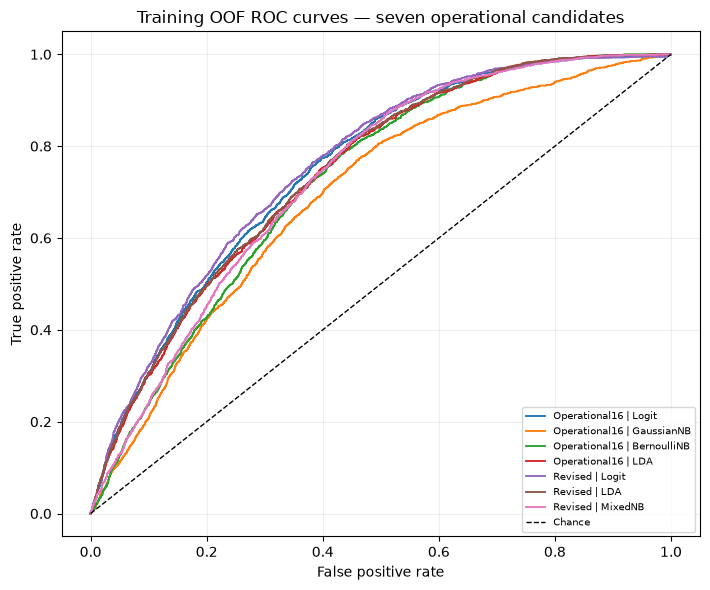

Winner by mean five-fold ROC-AUC: Revised | Logit (AUC 0.757647, fold SE 0.005821).
Exact-tie rule: alphabetical candidate label. Exact ties: ['Revised | Logit'].
Operational16 | Logit: AUC gap from winner 0.007627; within selected winner one-SE range=False.
Operational16 | GaussianNB: AUC gap from winner 0.065626; within selected winner one-SE range=False.
Operational16 | BernoulliNB: AUC gap from winner 0.034514; within selected winner one-SE range=False.
Operational16 | LDA: AUC gap from winner 0.016768; within selected winner one-SE range=False.
Revised | Logit: AUC gap from winner 0.000000; within selected winner one-SE range=True.
Revised | LDA: AUC gap from winner 0.013918; within selected winner one-SE range=False.
Revised | MixedNB: AUC gap from winner 0.026173; within selected winner one-SE range=False.
One-SE proximity is descriptive only; no model is substituted for the highest mean AUC.


In [11]:
OPERATIONAL_LABELS=['Operational16 | Logit','Operational16 | GaussianNB',
    'Operational16 | BernoulliNB','Operational16 | LDA',
    'Revised | Logit','Revised | LDA','Revised | MixedNB']
# Admission gate: seven complete operational OOF vectors, common fold coverage, and both unpenalised Logits numerically accepted.
if len(OPERATIONAL_LABELS)!=7 or len(set(OPERATIONAL_LABELS))!=7:
    raise RuntimeError('The operational comparison must contain exactly seven distinct candidates.')
for label in OPERATIONAL_LABELS:
    r=RESULTS[label]; oof=np.asarray(r.get('oof'),dtype=float)
    if r.get('status')!='SCORED' or len(r.get('folds',[]))!=K or oof.shape!=(len(ytr),):
        raise RuntimeError(f'{label}: failed scoring or missing OOF/fold evidence.')
    if not np.isfinite(oof).all() or not np.all((oof>=0)&(oof<=1)):
        raise RuntimeError(f'{label}: OOF probabilities are non-finite or outside [0,1].')
    coverage=np.zeros(len(ytr),dtype=int)
    for expected_fold,((fit_idx,val_idx),fold) in enumerate(zip(FOLD_INDICES,r['folds']),1):
        if int(fold.get('fold',-1))!=expected_fold or fold.get('fit_status')!='OK' or int(fold.get('n_validation',-1))!=len(val_idx):
            raise RuntimeError(f'{label}: invalid fold status or validation coverage in fold {expected_fold}.')
        if not fold.get('finite_model_parameters',False) or not fold.get('finite_probabilities',False) or not fold.get('probabilities_in_0_1',False):
            raise RuntimeError(f'{label}: non-finite fitted parameters or probabilities in fold {expected_fold}.')
        coverage[val_idx]+=1
        yv=ytr.iloc[val_idx].to_numpy(); pv=oof[val_idx]
        if (not np.isclose(roc_auc_score(yv,pv),float(fold['roc_auc']),rtol=0,atol=1e-12)
            or not np.isclose(average_precision_score(yv,pv),float(fold['average_precision']),rtol=0,atol=1e-12)):
            raise RuntimeError(f'{label}: saved fold scores do not match its OOF vector in fold {expected_fold}.')
    if not np.all(coverage==1):
        raise RuntimeError(f'{label}: every training row must have exactly one validation prediction.')
for label in ['All17 | Logit','Operational16 | Logit','Revised | Logit']:
    for fold in RESULTS[label]['folds']:
        if (not bool(fold.get('reference_passes_fixed_criteria',False))
            or not bool(fold.get('finite_model_parameters',False))
            or not bool(fold.get('finite_probabilities',False))
            or not bool(fold.get('probabilities_in_0_1',False))):
            raise RuntimeError(f'{label}: required finite-parameter/probability or IRLS gate failed in fold {fold.get("fold")}; stop before winner selection.')

cv_rows=[]
for label in OPERATIONAL_LABELS:
    r=RESULTS[label]
    cv_rows.append({'candidate':label,'mean_fold_auc':r['mean_fold_auc'],
      'auc_fold_sd':r['fold_auc_sd'],'auc_fold_se':r['fold_auc_se'],
      'mean_fold_ap':r['mean_fold_ap'],'ap_fold_sd':r['fold_ap_sd'],'ap_fold_se':r['fold_ap_se'],
      'numerical_status':compact_numerical_label(r),'warning_count':len(r['warnings'])})
SEVEN_CV=pd.DataFrame(cv_rows)
max_auc=float(SEVEN_CV.mean_fold_auc.max())
exact_ties=sorted(SEVEN_CV.loc[SEVEN_CV.mean_fold_auc.eq(max_auc),'candidate'].tolist())
WINNER_LABEL=exact_ties[0]
WINNER_SE=float(SEVEN_CV.loc[SEVEN_CV.candidate.eq(WINNER_LABEL),'auc_fold_se'].iloc[0])
SEVEN_CV['within_winner_one_se']=SEVEN_CV.mean_fold_auc.ge(max_auc-WINNER_SE)
SEVEN_CV['selected_by_primary_auc']=SEVEN_CV.candidate.eq(WINNER_LABEL)
display(SEVEN_CV.round(6))
SEVEN_CV.to_csv(ARTIFACTS/'seven_candidate_cv.csv',index=False)

fold_score_rows=[]; oof_rows=[]
for label in OPERATIONAL_LABELS:
    r=RESULTS[label]
    for fold in r['folds']:
        fold_score_rows.append({'candidate':label,'fold':int(fold['fold']),
          'roc_auc':float(fold['roc_auc']),'average_precision':float(fold['average_precision']),
          'n_validation':int(fold['n_validation'])})
    for row_id,y_true,score in zip(Xtr.index.to_numpy(),ytr.to_numpy(),r['oof']):
        oof_rows.append({'candidate':label,'row_id':int(row_id),'observed':int(y_true),
          'oof_probability':float(score)})
SEVEN_FOLD_SCORES=pd.DataFrame(fold_score_rows)
SEVEN_OOF=pd.DataFrame(oof_rows)
SEVEN_FOLD_SCORES.to_csv(ARTIFACTS/'seven_candidate_fold_scores.csv',index=False)
SEVEN_OOF.to_csv(ARTIFACTS/'seven_candidate_oof_predictions.csv',index=False,float_format='%.17g')

fig,ax=plt.subplots(figsize=(7.2,6))
for label in OPERATIONAL_LABELS:
    fpr,tpr,_=roc_curve(ytr,RESULTS[label]['oof'],drop_intermediate=False)
    ax.plot(fpr,tpr,lw=1.35,label=label)
ax.plot([0,1],[0,1],color='black',lw=1,linestyle='--',label='Chance')
ax.set(xlabel='False positive rate',ylabel='True positive rate',
       title='Training OOF ROC curves — seven operational candidates')
ax.legend(fontsize=7,loc='lower right'); ax.grid(alpha=.2); fig.tight_layout()
fig.savefig(ARTIFACTS/'training_oof_roc_seven.png',dpi=180,bbox_inches='tight')
display(fig); plt.close(fig)
WINNER_OOF=np.asarray(RESULTS[WINNER_LABEL]['oof'],dtype=float)
print(f'Winner by mean five-fold ROC-AUC: {WINNER_LABEL} (AUC {max_auc:.6f}, fold SE {WINNER_SE:.6f}).')
print(f'Exact-tie rule: alphabetical candidate label. Exact ties: {exact_ties}.')
for _,r in SEVEN_CV.iterrows():
    print(f"{r.candidate}: AUC gap from winner {max_auc-r.mean_fold_auc:.6f}; within selected winner one-SE range={bool(r.within_winner_one_se)}.")
print('One-SE proximity is descriptive only; no model is substituted for the highest mean AUC.')

## 9. Selected-model training OOF probability distribution (A9)

**Purpose.** Check whether selected-model scores concentrate near zero or one, or spread across sessions. **Method.** Plot the selected model's training out-of-fold probabilities separately by observed outcome. **Implication.** This is score distribution evidence only; ROC-AUC is a ranking metric and does not establish calibration.

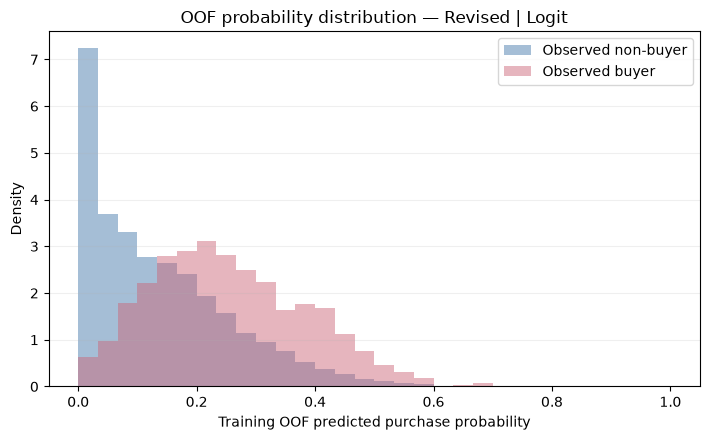

,observed_group,sessions,mean_probability,median_probability,share_below_0.10,share_below_0.50,share_above_0.90,maximum_probability
0,Observed non-buyer,8338,0.13639,0.10843,0.47409,0.99101,0.0,0.85908
1,Observed buyer,1526,0.25458,0.24145,0.11337,0.96396,0.0,0.68782


Nonbuyer OOF mean/median=0.1364/0.1084; buyer mean/median=0.2546/0.2414. Scores are below .50 for 99.1% of nonbuyers and 96.4% of buyers; at most 0.0% exceed .90 and the largest is 0.859. This concentration explains very few buyer predictions and near-universal voucher coverage at the fixed 2/3 cutoff, but does not establish calibration.


In [12]:
fig,ax=plt.subplots(figsize=(7.2,4.5))
for cls,color,name in [(0,'#4477AA','Observed non-buyer'),(1,'#CC6677','Observed buyer')]:
    ax.hist(WINNER_OOF[np.asarray(ytr)==cls],bins=np.linspace(0,1,31),
            density=True,alpha=.48,color=color,label=name)
ax.set(xlabel='Training OOF predicted purchase probability',ylabel='Density',
       title=f'OOF probability distribution — {WINNER_LABEL}')
ax.legend(); ax.grid(axis='y',alpha=.2); fig.tight_layout()
fig.savefig(ARTIFACTS/'training_winner_oof_probability_histogram.png',dpi=180,bbox_inches='tight')
display(fig); plt.close(fig)
hist_rows=[]
for cls,name in [(0,'Observed non-buyer'),(1,'Observed buyer')]:
    values=WINNER_OOF[np.asarray(ytr)==cls]
    hist_rows.append({'observed_group':name,'sessions':len(values),'mean_probability':float(values.mean()),
      'median_probability':float(np.median(values)),'share_below_0.10':float(np.mean(values<.10)),
      'share_below_0.50':float(np.mean(values<.50)),'share_above_0.90':float(np.mean(values>.90)),
      'maximum_probability':float(values.max())})
WINNER_HIST_SUMMARY=pd.DataFrame(hist_rows)
display(WINNER_HIST_SUMMARY.round(5))
hist_nonbuyer=WINNER_HIST_SUMMARY.loc[WINNER_HIST_SUMMARY.observed_group.eq('Observed non-buyer')].iloc[0]
hist_buyer=WINNER_HIST_SUMMARY.loc[WINNER_HIST_SUMMARY.observed_group.eq('Observed buyer')].iloc[0]
share_high=max(hist_nonbuyer['share_above_0.90'],hist_buyer['share_above_0.90'])
print(f"Nonbuyer OOF mean/median={hist_nonbuyer.mean_probability:.4f}/{hist_nonbuyer.median_probability:.4f}; buyer mean/median={hist_buyer.mean_probability:.4f}/{hist_buyer.median_probability:.4f}. Scores are below .50 for {hist_nonbuyer['share_below_0.50']:.1%} of nonbuyers and {hist_buyer['share_below_0.50']:.1%} of buyers; at most {share_high:.1%} exceed .90 and the largest is {max(hist_nonbuyer['maximum_probability'],hist_buyer['maximum_probability']):.3f}. This concentration explains very few buyer predictions and near-universal voucher coverage at the fixed 2/3 cutoff, but does not establish calibration.")

## 10. Four fixed threshold references (A10)

**Purpose.** Show how four supported operating points change buyer detection, voucher coverage, and hypothetical revenue arithmetic for the selected model. **Method.** Use exactly the training purchase base rate, 0.500, primary 2/3, and the sensitivity-specificity crossover. A voucher is assigned when probability is below threshold. With discount d=.20 and assumed q=.50, C_FN=.20A and C_FP=.80×.50A=.40A, giving t*=.40/(.40+.20)=2/3 when probabilities are meaningful. Compute TP/FP/FN/TN, rates, voucher share and revenue at q=.50; verify against per-session arithmetic. **Implication.** Keep 2/3 as primary regardless of simulated revenue; it is not empirically optimal by guarantee. No revenue-maximising threshold scan is performed.

With d=0.20 and assumed q_ref=0.50: C_FN/A=0.20, C_FP/A=0.40, t*=C_FP/(C_FP+C_FN)=0.66666667; this rationale requires meaningful probabilities.


,reference,threshold,sensitivity,specificity,precision,TP,FP,FN,TN,voucher_count,voucher_share,R0_over_A,Rq_over_A,delta_R_over_A,relative_delta_vs_R0,direct_expected_revenue_over_A
0,Training purchase base rate,0.15470,0.75295,0.62533,0.26890,1149,3124,377,5214,5591,0.56681,1526.0,3536.2,2010.2,1.31730,3536.2
1,Conventional 0.500,0.50000,0.03604,0.99101,0.42308,55,75,1471,8263,9734,0.98682,1526.0,4537.0,3011.0,1.97313,4537.0
2,Primary cost-based 2/3,0.66667,0.00262,0.99976,0.66667,4,2,1522,8336,9858,0.99939,1526.0,4556.0,3030.0,1.98558,4556.0
3,Sensitivity-specificity crossover,0.17961,0.68349,0.68350,0.28327,1043,2639,483,5699,6182,0.62672,1526.0,3709.0,2183.0,1.43054,3709.0


At the fixed 2/3 primary threshold, sensitivity is 0.0026, specificity is 0.9998, and 99.94% of sessions receive a voucher. The cost-based threshold yields a very low sensitivity here; it is retained as precommitted and is not represented as empirically optimal.
At 2/3, only 6 of 9,864 sessions are predicted buyers and 9,858 receive vouchers; 4/1,526 actual buyers are detected. This has very little policy selectivity despite the model mean AUC of 0.757647.


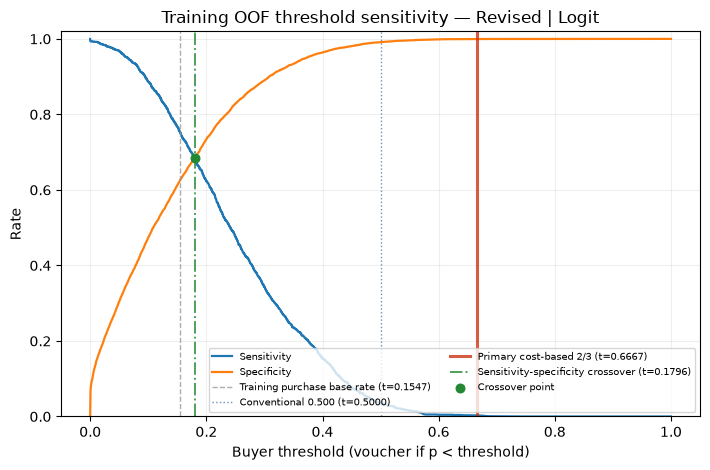

Sensitivity-specificity crossover is 0.17961341; exact ties use the lower threshold.
The primary threshold remains exactly 2/3. Relative delta is delta/R0 under common A; it is hypothetical, not measured uplift or profit.


In [13]:
POLICY_DISCOUNT=.20; Q_REFERENCE=.50
C_FN_PER_A=POLICY_DISCOUNT
C_FP_PER_A=(1-POLICY_DISCOUNT)*Q_REFERENCE
COST_THRESHOLD=C_FP_PER_A/(C_FP_PER_A+C_FN_PER_A)
if not np.isclose(COST_THRESHOLD,2/3,rtol=0,atol=1e-15):
    raise AssertionError('The fixed cost derivation must equal 2/3.')
print(f'With d={POLICY_DISCOUNT:.2f} and assumed q_ref={Q_REFERENCE:.2f}: C_FN/A={C_FN_PER_A:.2f}, C_FP/A={C_FP_PER_A:.2f}, t*=C_FP/(C_FP+C_FN)={COST_THRESHOLD:.8f}; this rationale requires meaningful probabilities.')

def threshold_metrics(y_true,probability,threshold,q=.50,discount=.20):
    y=np.asarray(y_true,dtype=int); p=np.asarray(probability,dtype=float)
    pred=(p>=threshold).astype(int); voucher=(pred==0)
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    precision=float(tp/(tp+fp)) if (tp+fp)>0 else None
    sensitivity=float(tp/(tp+fn)) if (tp+fn)>0 else np.nan
    specificity=float(tn/(tn+fp)) if (tn+fp)>0 else np.nan
    r0=float(tp+fn)
    rq=float(tp+(1-discount)*fn+(1-discount)*q*tn)
    delta=rq-r0
    direct=np.where(y==1,np.where(voucher,1-discount,1.0),
                    np.where(voucher,(1-discount)*q,0.0)).sum()
    if not np.isclose(rq,direct,rtol=0,atol=1e-10):
        raise AssertionError('Voucher formula disagrees with row-level expected revenue.')
    return {'threshold':float(threshold),'sensitivity':sensitivity,'specificity':specificity,
      'precision':precision,'TP':int(tp),'FP':int(fp),'FN':int(fn),'TN':int(tn),
      'voucher_count':int(voucher.sum()),'voucher_share':float(voucher.mean()),
      'R0_over_A':r0,'Rq_over_A':rq,'delta_R_over_A':delta,
      'relative_delta_vs_R0':(delta/r0 if r0 else None),
      'direct_expected_revenue_over_A':float(direct)}

roc_fpr,roc_tpr,roc_thresholds=roc_curve(ytr,WINNER_OOF,drop_intermediate=False)
crossover_rows=[]
for fpr,tpr,t in zip(roc_fpr,roc_tpr,roc_thresholds):
    if np.isfinite(t) and 0<=t<=1:
        crossover_rows.append({'threshold':float(t),'sensitivity':float(tpr),
          'specificity':float(1-fpr),'absolute_rate_gap':float(abs(tpr-(1-fpr)))})
# Include fixed probability endpoints; calculate rates only, without policy/revenue arithmetic.
crossover_rows.append({'threshold':0.0,'sensitivity':1.0,'specificity':0.0,'absolute_rate_gap':1.0})
pred_at_one=(WINNER_OOF>=1.0).astype(int)
tn1,fp1,fn1,tp1=confusion_matrix(ytr,pred_at_one,labels=[0,1]).ravel()
sens1=float(tp1/(tp1+fn1)); spec1=float(tn1/(tn1+fp1))
crossover_rows.append({'threshold':1.0,'sensitivity':sens1,'specificity':spec1,
  'absolute_rate_gap':abs(sens1-spec1)})
CROSSOVER_ROW=min(crossover_rows,key=lambda r:(r['absolute_rate_gap'],r['threshold']))
CROSSOVER_THRESHOLD=float(CROSSOVER_ROW['threshold'])
THRESHOLD_REFERENCES=[
    ('Training purchase base rate',float(np.mean(ytr))),
    ('Conventional 0.500',.5),
    ('Primary cost-based 2/3',2/3),
    ('Sensitivity-specificity crossover',CROSSOVER_THRESHOLD)]
THRESHOLD_TABLE=pd.DataFrame([
    {'reference':label,**threshold_metrics(ytr,WINNER_OOF,t,q=Q_REFERENCE,discount=POLICY_DISCOUNT)}
    for label,t in THRESHOLD_REFERENCES])
THRESHOLD_TABLE.to_csv(ARTIFACTS/'winner_four_thresholds.csv',index=False)
THRESHOLD_CURVE=pd.DataFrame(crossover_rows).sort_values('threshold').reset_index(drop=True)
THRESHOLD_CURVE.to_csv(ARTIFACTS/'winner_threshold_sensitivity_curve.csv',index=False)
display(THRESHOLD_TABLE.round(5))
primary_threshold_row=THRESHOLD_TABLE.loc[THRESHOLD_TABLE.reference.eq('Primary cost-based 2/3')].iloc[0]
print(f"At the fixed 2/3 primary threshold, sensitivity is {primary_threshold_row.sensitivity:.4f}, specificity is {primary_threshold_row.specificity:.4f}, and {primary_threshold_row.voucher_share:.2%} of sessions receive a voucher. The cost-based threshold yields a very low sensitivity here; it is retained as precommitted and is not represented as empirically optimal.")
print(f"At 2/3, only {int(primary_threshold_row.TP+primary_threshold_row.FP):,} of {len(ytr):,} sessions are predicted buyers and {int(primary_threshold_row.voucher_count):,} receive vouchers; {int(primary_threshold_row.TP):,}/{int(primary_threshold_row.TP+primary_threshold_row.FN):,} actual buyers are detected. This has very little policy selectivity despite the model mean AUC of {max_auc:.6f}.")
fig,ax=plt.subplots(figsize=(7.2,4.8))
ax.plot(THRESHOLD_CURVE.threshold,THRESHOLD_CURVE.sensitivity,label='Sensitivity',lw=1.6)
ax.plot(THRESHOLD_CURVE.threshold,THRESHOLD_CURVE.specificity,label='Specificity',lw=1.6)
reference_styles=[('#999999','--',1.0),('#4477AA',':',1.0),('#CC3311','-',2.2),('#228833','-.',1.4)]
for (label,t),(color,style,width) in zip(THRESHOLD_REFERENCES,reference_styles):
    ax.axvline(t,color=color,lw=width,alpha=.8,linestyle=style,label=f'{label} (t={t:.4f})')
ax.scatter([CROSSOVER_THRESHOLD],[CROSSOVER_ROW['sensitivity']],s=38,marker='o',
           color='#228833',zorder=5,label='Crossover point')
ax.set(xlabel='Buyer threshold (voucher if p < threshold)',ylabel='Rate',ylim=(0,1.02),
       title=f'Training OOF threshold sensitivity — {WINNER_LABEL}')
ax.grid(alpha=.2); ax.legend(fontsize=7,ncol=2); fig.tight_layout()
fig.savefig(ARTIFACTS/'winner_threshold_sensitivity.png',dpi=180,bbox_inches='tight')
display(fig); plt.close(fig)
print(f'Sensitivity-specificity crossover is {CROSSOVER_THRESHOLD:.8f}; exact ties use the lower threshold.')
print('The primary threshold remains exactly 2/3. Relative delta is delta/R0 under common A; it is hypothetical, not measured uplift or profit.')

## 11. Fixed conversion-rate scenarios and training freeze (A11)

**Purpose.** Show how the unknown incremental conversion assumption changes the same selected-model assignments at the precommitted 2/3 policy. **Method.** Hold model, OOF predictions, recipients, discount 0.20, and common order-value unit A fixed; vary only q over 0.10, 0.25, 0.50, and 1.00. Verify each total against row-level expected revenue. **Implication.** q is not identified by these records. The results are hypothetical arithmetic, not measured voucher effects; model and threshold remain unchanged.

,q_incremental_conversion,threshold,discount,voucher_count_fixed,voucher_share_fixed,R0_over_A,Rq_over_A,delta_R_over_A,relative_delta_vs_R0,direct_expected_revenue_over_A
0,0.10,0.66667,0.2,9858,0.99939,1526.0,1888.48,362.48,0.23754,1888.48
1,0.25,0.66667,0.2,9858,0.99939,1526.0,2888.80,1362.80,0.89305,2888.80
2,0.50,0.66667,0.2,9858,0.99939,1526.0,4556.00,3030.00,1.98558,4556.00
3,1.00,0.66667,0.2,9858,0.99939,1526.0,7890.40,6364.40,4.17064,7890.40


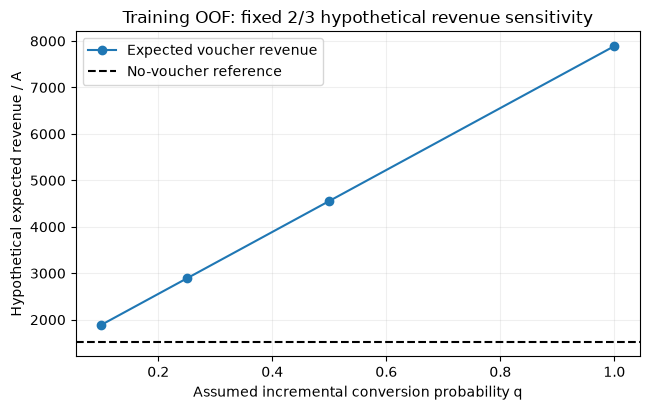

At 2/3: TP=4, FP=2, FN=1522, TN=8336; fixed voucher count=9858.
The increase from R0 to Rq is driven by the assumed incremental conversion of the 8,336 actual nonbuyers receiving vouchers, not an observed targeting benefit or measured growth. At q=.50, the formula adds .80 x .50 x 8,336 = 3,334.4 normalized A units by assumption.
Only the assumed q changes across scenarios; these hypothetical totals are not actual revenue or profit.
Training freeze written with the independently reviewed training decision; A12 guards still precede holdout reload.


In [14]:
PRIMARY_THRESHOLD=2/3; DISCOUNT=.20; Q_REFERENCE=.50; Q_SCENARIOS=[.10,.25,.50,1.00]
PRIMARY_POLICY=threshold_metrics(ytr,WINNER_OOF,PRIMARY_THRESHOLD,q=Q_REFERENCE,discount=DISCOUNT)
primary_pred=(WINNER_OOF>=PRIMARY_THRESHOLD).astype(int); primary_voucher=(primary_pred==0)
tn,fp,fn,tp=(PRIMARY_POLICY[k] for k in ['TN','FP','FN','TP'])
q_rows=[]
for q in Q_SCENARIOS:
    r0=float(tp+fn); rq=float(tp+(1-DISCOUNT)*fn+(1-DISCOUNT)*q*tn); delta=rq-r0
    direct=np.where(np.asarray(ytr)==1,np.where(primary_voucher,1-DISCOUNT,1.0),
                    np.where(primary_voucher,(1-DISCOUNT)*q,0.0)).sum()
    if not np.isclose(rq,direct,rtol=0,atol=1e-10):
        raise AssertionError(f'q={q}: formula/direct arithmetic mismatch')
    q_rows.append({'q_incremental_conversion':q,'threshold':PRIMARY_THRESHOLD,'discount':DISCOUNT,
      'voucher_count_fixed':PRIMARY_POLICY['voucher_count'],'voucher_share_fixed':PRIMARY_POLICY['voucher_share'],
      'R0_over_A':r0,'Rq_over_A':rq,'delta_R_over_A':delta,
      'relative_delta_vs_R0':(delta/r0 if r0 else None),'direct_expected_revenue_over_A':float(direct)})
Q_SCENARIO_TABLE=pd.DataFrame(q_rows)
Q_SCENARIO_TABLE.to_csv(ARTIFACTS/'winner_q_scenarios_at_two_thirds.csv',index=False)
display(Q_SCENARIO_TABLE.round(5))
fig,ax=plt.subplots(figsize=(6.6,4.2))
ax.plot(Q_SCENARIO_TABLE.q_incremental_conversion,Q_SCENARIO_TABLE.Rq_over_A,
        marker='o',label='Expected voucher revenue')
ax.axhline(Q_SCENARIO_TABLE.R0_over_A.iloc[0],color='black',linestyle='--',
           label='No-voucher reference')
ax.set(xlabel='Assumed incremental conversion probability q',ylabel='Hypothetical expected revenue / A',
       title='Training OOF: fixed 2/3 hypothetical revenue sensitivity')
ax.grid(alpha=.2); ax.legend(); fig.tight_layout()
fig.savefig(ARTIFACTS/'winner_q_scenario_sensitivity.png',dpi=180,bbox_inches='tight')
display(fig); plt.close(fig)
print(f'At 2/3: TP={tp}, FP={fp}, FN={fn}, TN={tn}; fixed voucher count={PRIMARY_POLICY["voucher_count"]}.')
print(f"The increase from R0 to Rq is driven by the assumed incremental conversion of the {tn:,} actual nonbuyers receiving vouchers, not an observed targeting benefit or measured growth. At q=.50, the formula adds .80 x .50 x {tn:,} = {.8*.5*tn:,.1f} normalized A units by assumption.")
print('Only the assumed q changes across scenarios; these hypothetical totals are not actual revenue or profit.')

def json_clean(v):
    if isinstance(v,dict): return {str(k):json_clean(x) for k,x in v.items()}
    if isinstance(v,(list,tuple)): return [json_clean(x) for x in v]
    if isinstance(v,(np.integer,)): return int(v)
    if isinstance(v,(np.floating,float)):
        x=float(v); return x if np.isfinite(x) else None
    if isinstance(v,(np.bool_,)): return bool(v)
    return v

zero_shares={c:float(Xtr[c].eq(0).mean()) for c in ACTIVITY}
recipe_details={
 'Operational16 | Logit':{'family':'Logit','C':'Infinity','solver':'newton-cg','tol':1e-8,'max_iter':2000,'representation':'Raw numeric magnitudes including SpecialDay; six nominal fields k-1 OHE; Weekend 0/1.'},
 'Operational16 | GaussianNB':{'family':'GaussianNB','var_smoothing':'scikit-learn default','representation':'Raw numeric magnitudes including SpecialDay; six nominal fields full k OHE; Weekend 0/1.'},
 'Operational16 | BernoulliNB':{'family':'BernoulliNB','alpha':1.0,'binarize':None,'representation':'Numeric >0 indicators; six nominal fields full k OHE; Weekend 0/1.'},
 'Operational16 | LDA':{'family':'LDA','solver':'svd','representation':'Raw numeric magnitudes including SpecialDay; six nominal fields k-1 OHE; Weekend 0/1.'},
 'Revised | Logit':{'family':'Logit','C':'Infinity','solver':'newton-cg','tol':1e-8,'max_iter':2000,'representation':'All 16 sources; log1p six activity columns; add >0 indicators only when fit-fold zero share >=.50; raw BounceRates/ExitRates/SpecialDay/Weekend; k-1 OHE.',
   'fold_zero_shares':{str(r['fold']):json.loads(r['fold_zero_share']) for r in RESULTS['Revised | Logit']['folds']},
   'fold_presence_columns':{str(r['fold']):json.loads(r['fold_presence_columns']) for r in RESULTS['Revised | Logit']['folds']}},
 'Revised | LDA':{'family':'LDA','solver':'svd','representation':'All 16 sources; log1p six activity columns; raw BounceRates/ExitRates/SpecialDay/Weekend; k-1 OHE.'},
 'Revised | MixedNB':{'family':'MixedGaussianCategoricalNB','alpha':1.0,'GaussianNB_var_smoothing':'scikit-learn default',
   'prior':'Empirical prior appears once in Gaussian posterior; categorical likelihoods are added and normalized by logsumexp.',
   'representation':'All 16 sources; Gaussian block log1p six activity plus raw BounceRates/ExitRates; categorical block six nominal + Weekend 0/1 + SpecialDay>0, fit-fold maps reserve unknown code 0 and Laplace support.'}}
train_ids=Xtr.index.to_numpy(dtype=int).tolist()
reserved_test_ids=[int(x) for x in test_ids]
fold_ids=[{'fold':i+1,'fit_row_ids':Xtr.index.to_numpy()[fit].astype(int).tolist(),
           'validation_row_ids':Xtr.index.to_numpy()[val].astype(int).tolist()}
          for i,(fit,val) in enumerate(FOLD_INDICES)]
freeze={
 'status':'TRAINING DECISION PASSED INDEPENDENT PRE-TEST REVIEW; TEST ACCESS ONLY AFTER A12 GUARDS',
 'pretest_review':'docs/pretest_review.md (PASS, 2026-10-25)',
 'winner_label':WINNER_LABEL,'winner_exact_recipe':recipe_details[WINNER_LABEL],
 'operational_selection_rule':'Highest mean five-fold ROC-AUC across exactly seven operational candidates; exact ties broken alphabetically by candidate label. One-SE proximity is descriptive only; AP and voucher revenue do not select.',
 'seven_candidate_cv':SEVEN_CV.to_dict(orient='records'),
 'seed':SEED,'test_size':TEST_FRAC,'training_row_ids':train_ids,'reserved_test_row_ids':reserved_test_ids,
 'fold_ids':fold_ids,'source_csv_sha256':source_hash,'source_columns':SAFE,
 'primary_threshold':PRIMARY_THRESHOLD,'discount':DISCOUNT,'q_reference':Q_REFERENCE,
 'threshold_reference_values':{label:float(t) for label,t in THRESHOLD_REFERENCES},
 'primary_policy_training_oof_counts':{k:int(PRIMARY_POLICY[k]) for k in ['TP','FP','FN','TN','voucher_count']},
 'training_policy_and_scenarios_use_oof_only':True,'test_predictions_or_outcomes_accessed':False}
freeze=json_clean(freeze)
with (ARTIFACTS/'training_freeze.json').open('w') as f:
    json.dump(freeze,f,indent=2,allow_nan=False); f.write('\n')
print('Training freeze written with the independently reviewed training decision; A12 guards still precede holdout reload.')

In [15]:
# Persist the reviewed training-stage candidate evidence before the single-winner holdout audit.
summary_rows=[]
for label,r in RESULTS.items():
    summary_rows.append({'candidate':label,'stage':r['stage'],'scoring_status':r['status'],'numerical_status':r['numerical_status'],
      'mean_fold_auc':r.get('mean_fold_auc',np.nan),'fold_auc_sd':r.get('fold_auc_sd',np.nan),'fold_auc_se':r.get('fold_auc_se',np.nan),
      'mean_fold_ap':r.get('mean_fold_ap',np.nan),'fold_ap_sd':r.get('fold_ap_sd',np.nan),'fold_ap_se':r.get('fold_ap_se',np.nan),
      'pooled_oof_auc':r.get('pooled_oof_auc',np.nan),'pooled_oof_ap':r.get('pooled_oof_ap',np.nan),'warning_count':len(r['warnings']),'failure':r['failure']})
model_summary=pd.DataFrame(summary_rows)
baseline_summary=model_summary[~model_summary.candidate.str.startswith('Revised | ')].copy()
baseline_folds=pd.DataFrame(FOLD_ROWS)
baseline_folds=baseline_folds[~baseline_folds.candidate.str.startswith('Revised | ')].copy()
model_warnings=pd.DataFrame(WARNING_ROWS,columns=['candidate','fold','warning_type','message'])
baseline_warnings=model_warnings[~model_warnings.candidate.str.startswith('Revised | ')].copy()
baseline_summary.to_csv(ARTIFACTS/'baseline_summary.csv',index=False)
model_summary.to_csv(ARTIFACTS/'model_summary.csv',index=False)
with (ARTIFACTS/'baseline_summary.json').open('w') as f: json.dump(json_clean(baseline_summary.to_dict(orient='records')),f,indent=2,allow_nan=False); f.write('\n')
with (ARTIFACTS/'model_summary.json').open('w') as f: json.dump(json_clean(model_summary.to_dict(orient='records')),f,indent=2,allow_nan=False); f.write('\n')
baseline_folds.to_csv(ARTIFACTS/'baseline_fold_metrics_diagnostics.csv',index=False)
model_summary_folds=pd.DataFrame(FOLD_ROWS)
model_summary_folds.to_csv(ARTIFACTS/'model_fold_metrics_diagnostics.csv',index=False)
baseline_warnings.to_csv(ARTIFACTS/'baseline_warnings.csv',index=False)
model_warnings.to_csv(ARTIFACTS/'model_warnings.csv',index=False)
for label,r in RESULTS.items():
    if r['oof'] is not None:
        slug_map={'All17 | Logit':'all17_Logit','All17 | GaussianNB':'all17_gaussian_nb','All17 | BernoulliNB':'all17_bernoulli_nb','All17 | LDA':'all17_LDA',
          'Operational16 | Logit':'operational16_Logit','Operational16 | GaussianNB':'operational16_gaussian_nb','Operational16 | BernoulliNB':'operational16_bernoulli_nb','Operational16 | LDA':'operational16_LDA',
          'Revised | Logit':'revised_Logit','Revised | LDA':'revised_LDA','Revised | MixedNB':'revised_MixedNB'}
        slug=slug_map[label]
        pd.DataFrame({'row_id':Xtr.index,'observed':ytr.to_numpy(),'oof_probability':r['oof']}).to_csv(ARTIFACTS/(slug+'_oof.csv'),index=False,float_format='%.17g')
print('Saved canonical eight-baseline artifacts separately from all-eleven-model summaries, fold diagnostics, warnings and OOF vectors. These files contain training-stage evidence only; the A12 single-winner audit follows.')
print(f'Elapsed notebook modelling-stage time: {time.perf_counter()-RUN_START:.1f} seconds.')

Saved canonical eight-baseline artifacts separately from all-eleven-model summaries, fold diagnostics, warnings and OOF vectors. These files contain training-stage evidence only; the A12 single-winner audit follows.
Elapsed notebook modelling-stage time: 282.1 seconds.


## 12. Single-winner held-out audit (A12)

**Purpose.** Audit only the CV-selected specification once on the reserved sessions, using the already fixed policy. **Method.** First verify the reviewed training freeze, all required candidate/numerical gates, source hash and exact winner/policy. Fit a clone of the frozen pipeline on all training rows, then compare its training-only unpenalised likelihood and probabilities with the same Binomial IRLS reference. Only after those guards pass, reload reserved row IDs, score the winner once, save that vector immediately, and reuse it for every test metric and fixed-policy scenario. **Interpretation.** The AUC and average precision describe ranking; the confusion matrix and rates describe the precommitted 2/3 policy. The holdout was withheld from selection under this revised protocol; historical overlapping-sample exposure and duplicate patterns limit claims of independence. Nothing here estimates voucher treatment effects.


Exact winner refit on all 9,864 training rows; full-training IRLS gate passed with |mean NLL delta|=9.61e-10 and max probability delta=1.51e-06.
Full-training design rank 68/69; presence columns: ['Informational', 'Informational_Duration']; pure nominal levels: 5. No finite-MLE claim is made for pure levels.


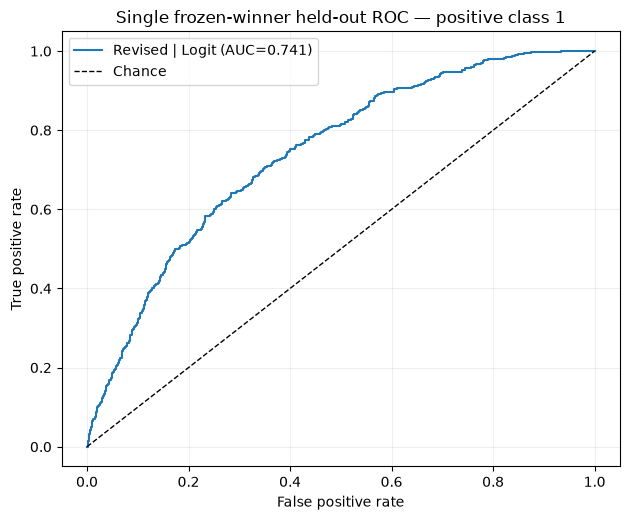

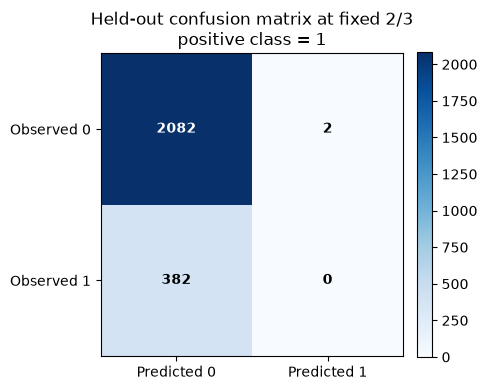

,q_incremental_conversion,voucher_count_fixed,R0_over_A,Rq_over_A,delta_R_over_A
0,0.10,2464,382.0,472.16,90.16
1,0.25,2464,382.0,722.00,340.00
2,0.50,2464,382.0,1138.40,756.40
3,1.00,2464,382.0,1971.20,1589.20


Held-out single-winner audit: ROC-AUC=0.741210; AP=0.326790; at fixed 2/3 sensitivity=0.0000, specificity=0.9990, precision=0.0000.
At fixed 2/3: TP=0, FP=2, FN=382, TN=2082; vouchers=2,464/2,466. q scenarios hold these assignments fixed and remain hypothetical.


In [16]:
# A12 — freeze and numerical guards happen before test rows are reloaded.
FREEZE_PATH=ARTIFACTS/'training_freeze.json'
FREEZE=json.loads(FREEZE_PATH.read_text())
FROZEN_REVIEWED_LABEL='Revised | Logit'
if WINNER_LABEL!=FROZEN_REVIEWED_LABEL or FREEZE.get('winner_label')!=FROZEN_REVIEWED_LABEL:
    raise RuntimeError(f'Computed/frozen winner mismatch: computed={WINNER_LABEL!r}, frozen={FREEZE.get("winner_label")!r}')
if not np.isclose(PRIMARY_THRESHOLD,2/3,rtol=0,atol=0) or not np.isclose(FREEZE.get('primary_threshold',np.nan),2/3,rtol=0,atol=0):
    raise RuntimeError('The reviewed primary threshold must be exactly 2/3.')
if FREEZE.get('source_csv_sha256')!=source_hash or FREEZE.get('source_columns')!=SAFE:
    raise RuntimeError('Training freeze source hash/feature list does not match the current source.')
if FREEZE.get('pretest_review')!='docs/pretest_review.md (PASS, 2026-10-25)':
    raise RuntimeError('The recorded independent pre-test PASS is missing.')
if len(OPERATIONAL_LABELS)!=7 or set(OPERATIONAL_LABELS)!=set(FREEZE['seven_candidate_cv'][i]['candidate'] for i in range(7)):
    raise RuntimeError('Seven-candidate frozen comparison is incomplete or inconsistent.')
if set(RESULTS)!=set(['All17 | Logit','All17 | GaussianNB','All17 | BernoulliNB','All17 | LDA',*OPERATIONAL_LABELS]):
    raise RuntimeError('Expected all four all-17 diagnostics and seven operational candidates before audit.')
for label,result in RESULTS.items():
    if result.get('status')!='SCORED' or result.get('oof') is None or not np.isfinite(result['oof']).all() or len(result['folds'])!=K:
        raise RuntimeError(f'{label}: required complete finite OOF/fold evidence is absent.')
    for fold in result['folds']:
        if fold.get('fit_status')!='OK' or not fold.get('finite_model_parameters',False) or not fold.get('finite_probabilities',False) or not fold.get('probabilities_in_0_1',False):
            raise RuntimeError(f'{label}: invalid fold evidence before audit: {fold.get("fold")}')
        if label.endswith('| Logit') and not fold.get('reference_passes_fixed_criteria',False):
            raise RuntimeError(f'{label}: same-likelihood numerical gate failed in fold {fold.get("fold")}.')
if not np.array_equal(Xtr.index.to_numpy(dtype=int),np.asarray(FREEZE['training_row_ids'],dtype=int)):
    raise RuntimeError('Current sorted training IDs differ from the reviewed freeze.')
if len(Xtr)!=9864 or len(test_ids)!=2466 or set(Xtr.index).intersection(set(test_ids)):
    raise RuntimeError('Frozen train/holdout sizes or disjointness check failed.')

# The exact reviewed operational revision is produced by the same candidate factory used in CV.
WINNER_PIPELINE=clone(make_revision_pipeline('Logit'))
WINNER_PARAMS=WINNER_PIPELINE.named_steps['clf'].get_params()
if not (WINNER_PARAMS.get('C')==np.inf and WINNER_PARAMS.get('solver')=='newton-cg'
        and WINNER_PARAMS.get('tol')==1e-8 and WINNER_PARAMS.get('max_iter')==2000):
    raise RuntimeError(f'Winner estimator parameters differ from the reviewed recipe: {WINNER_PARAMS}')
AUDIT_WARNINGS=[]
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    WINNER_PIPELINE.fit(Xtr[SAFE],ytr)
AUDIT_WARNINGS=[{'type':w.category.__name__,'message':str(w.message)[:300]} for w in caught]
WINNER_PRE=WINNER_PIPELINE.named_steps['pre']; WINNER_EST=WINNER_PIPELINE.named_steps['clf']
Z_TRAIN,WINNER_RANK,WINNER_P,WINNER_CONDITION=design_diagnostics(WINNER_PRE,Xtr[SAFE])
WINNER_TRAIN_PROB=positive_probability(WINNER_EST,Z_TRAIN)
WINNER_FINITE,WINNER_PARAMETER_CHECKS=finite_fitted_parameters(WINNER_EST)
if any(issubclass(w.category,ConvergenceWarning) for w in caught):
    raise RuntimeError('Full-training winner fit emitted ConvergenceWarning; stop before test reload.')
if not WINNER_FINITE or not np.isfinite(WINNER_TRAIN_PROB).all() or np.any((WINNER_TRAIN_PROB<0)|(WINNER_TRAIN_PROB>1)):
    raise RuntimeError(f'Full-training winner fit has invalid parameters/probabilities: {WINNER_PARAMETER_CHECKS}')
if not np.isfinite(WINNER_EST.coef_).all() or not np.isfinite(WINNER_EST.intercept_).all():
    raise RuntimeError('Full-training winner coefficients/intercept are non-finite.')
A_TRAIN=np.column_stack([np.ones(len(Z_TRAIN)),Z_TRAIN])
start=np.r_[float(WINNER_EST.intercept_[0]),np.asarray(WINNER_EST.coef_[0],dtype=float)]
with warnings.catch_warnings(record=True) as ref_warnings:
    warnings.simplefilter('always')
    FULLTRAIN_IRLS=sm.GLM(ytr.to_numpy(),A_TRAIN,family=sm.families.Binomial()).fit(
        start_params=start,maxiter=200,tol=1e-10,method='IRLS',wls_method='pinv',disp=0)
ref_params=np.asarray(FULLTRAIN_IRLS.params,dtype=float)
ref_eta=A_TRAIN@ref_params
ref_train_prob=np.asarray(FULLTRAIN_IRLS.predict(A_TRAIN),dtype=float)
train_nll_primary=float(np.mean(np.logaddexp(0.0,WINNER_EST.decision_function(Z_TRAIN))-ytr.to_numpy()*WINNER_EST.decision_function(Z_TRAIN)))
train_nll_ref=float(np.mean(np.logaddexp(0.0,ref_eta)-ytr.to_numpy()*ref_eta))
train_nll_delta=float(abs(train_nll_primary-train_nll_ref))
train_prob_delta=float(np.max(np.abs(WINNER_TRAIN_PROB-ref_train_prob)))
FULLTRAIN_GATE=bool(FULLTRAIN_IRLS.converged and np.isfinite(ref_params).all() and np.isfinite(ref_eta).all()
    and np.isfinite(ref_train_prob).all() and np.all((ref_train_prob>=0)&(ref_train_prob<=1))
    and train_nll_delta<=1e-6 and train_prob_delta<=1e-3)
if not FULLTRAIN_GATE:
    raise RuntimeError(f'Full-training Logit reference gate failed before test reload: converged={FULLTRAIN_IRLS.converged}, NLL delta={train_nll_delta:.3g}, probability delta={train_prob_delta:.3g}')
WINNER_PURE_LEVELS=pure_category_levels(Xtr[SAFE],ytr,CAT)
FULLTRAIN_AUDIT={
 'model_label':WINNER_LABEL,'row_count':int(len(Xtr)),'source_columns':SAFE,
 'representation':'All 16 sources; log1p six activity columns; fit-population zero-share >=.50 adds activity presence indicators; raw rates/SpecialDay/Weekend; k-1 nominal encoding.',
 'presence_columns':list(WINNER_PRE.presence_columns_), 'zero_shares':WINNER_PRE.zero_share_,
 'design_rank':int(WINNER_RANK),'design_columns':int(WINNER_P),'normalized_condition_number':float(WINNER_CONDITION),
 'pure_nominal_levels':WINNER_PURE_LEVELS,'finite_parameter_checks':WINNER_PARAMETER_CHECKS,
 'max_abs_coefficient':float(np.max(np.abs(WINNER_EST.coef_))),'intercept':float(WINNER_EST.intercept_[0]),
 'iterations':int(np.max(WINNER_EST.n_iter_)),'convergence_warning':any(issubclass(w.category,ConvergenceWarning) for w in caught),'training_mean_nll':train_nll_primary,
 'irls_reference_mean_training_nll':train_nll_ref,'abs_mean_training_nll_delta':train_nll_delta,
 'max_training_probability_delta':train_prob_delta,'irls_converged':bool(FULLTRAIN_IRLS.converged),
 'irls_iterations':int(FULLTRAIN_IRLS.fit_history.get('iteration',-1)),
 'numerical_gate_passed':FULLTRAIN_GATE,'pipeline_warnings':AUDIT_WARNINGS,
 'irls_reference_warnings':[{'type':w.category.__name__,'message':str(w.message)[:300]} for w in ref_warnings],
 'finite_MLE_certified':False if WINNER_PURE_LEVELS else None}
with (ARTIFACTS/'winner_training_fullfit_audit.json').open('w') as f:
    json.dump(json_clean(FULLTRAIN_AUDIT),f,indent=2,allow_nan=False); f.write('\n')
print(f"Exact winner refit on all {len(Xtr):,} training rows; full-training IRLS gate passed with |mean NLL delta|={train_nll_delta:.3g} and max probability delta={train_prob_delta:.3g}.")
print(f"Full-training design rank {WINNER_RANK}/{WINNER_P}; presence columns: {WINNER_PRE.presence_columns_}; pure nominal levels: {len(WINNER_PURE_LEVELS)}. No finite-MLE claim is made for pure levels.")

# Only now verify source identity and reload the reserved IDs for the single frozen prediction call.
if hashlib.sha256(data_path.read_bytes()).hexdigest()!=FREEZE['source_csv_sha256']:
    raise RuntimeError('Source CSV hash changed after training freeze; refusing test access.')
source_for_audit=pd.read_csv(data_path)
source_for_audit.insert(0,'_row_id',np.arange(len(source_for_audit),dtype=int))
if set(source_for_audit.columns)-{'_row_id'} != EXPECTED:
    raise RuntimeError('Reloaded source schema differs from training schema.')
if hashlib.sha256(data_path.read_bytes()).hexdigest()!=FREEZE['source_csv_sha256']:
    raise RuntimeError('Source CSV changed during reload; refusing test scoring.')
TEST_IDS=np.asarray(FREEZE['reserved_test_row_ids'],dtype=int)
if not np.array_equal(TEST_IDS,np.asarray(test_ids,dtype=int)):
    raise RuntimeError('In-memory and frozen test row IDs differ.')
test_partition=source_for_audit.set_index('_row_id').loc[TEST_IDS].copy()
y_test=test_partition.pop(TARGET).astype(int)
X_test=test_partition.loc[:,SAFE].copy()
X_test[CAT]=X_test[CAT].astype('string')
X_test['Weekend']=pd.to_numeric(X_test['Weekend'],errors='raise').astype(int)
if len(X_test)!=2466 or not np.isin(y_test.to_numpy(),[0,1]).all():
    raise RuntimeError('Reserved test partition failed row-count/target checks.')
TEST_UNSEEN=unknown_category_counts(Xtr[SAFE],X_test,CAT)
# Exactly one winner probability call; immediately persist row IDs, labels, raw probabilities and fixed policy.
TEST_CLASSES=np.asarray(WINNER_PIPELINE.named_steps['clf'].classes_)
positive_index=np.flatnonzero(TEST_CLASSES==1)
if len(positive_index)!=1: raise RuntimeError(f'Winner has no unique positive class 1: {TEST_CLASSES}')
with warnings.catch_warnings(record=True) as test_pred_warnings:
    warnings.simplefilter('always')
    TEST_PROB=np.asarray(WINNER_PIPELINE.predict_proba(X_test[SAFE])[:,int(positive_index[0])],dtype=float)
TEST_PREDICTION_WARNINGS=[{'type':w.category.__name__,'message':str(w.message)[:300]} for w in test_pred_warnings]
if len(TEST_PROB)!=len(X_test) or not np.isfinite(TEST_PROB).all() or np.any((TEST_PROB<0)|(TEST_PROB>1)):
    raise RuntimeError('Single winner returned invalid test probabilities.')
TEST_PRED=(TEST_PROB>=PRIMARY_THRESHOLD).astype(int)
TEST_VOUCHER=(TEST_PRED==0)
TEST_PREDICTIONS=pd.DataFrame({'row_id':TEST_IDS,'observed':y_test.to_numpy(dtype=int),
    'probability_class_1':TEST_PROB,'predicted_class_at_2_3':TEST_PRED,'voucher_at_2_3':TEST_VOUCHER})
TEST_PREDICTIONS.to_csv(ARTIFACTS/'test_predictions.csv',index=False,float_format='%.17g')
with (ARTIFACTS/'test_unseen_categories.json').open('w') as f:
    json.dump(json_clean(TEST_UNSEEN),f,indent=2,allow_nan=False); f.write('\n')
with (ARTIFACTS/'test_prediction_warnings.json').open('w') as f:
    json.dump(json_clean(TEST_PREDICTION_WARNINGS),f,indent=2,allow_nan=False); f.write('\n')

# All held-out evaluation below reuses TEST_PROB / TEST_PRED; no other threshold or model is scored.
TEST_AUC=float(roc_auc_score(y_test,TEST_PROB)); TEST_AP=float(average_precision_score(y_test,TEST_PROB))
TEST_CM=confusion_matrix(y_test,TEST_PRED,labels=[0,1])
TN_TEST,FP_TEST,FN_TEST,TP_TEST=map(int,TEST_CM.ravel())
TEST_POLICY=threshold_metrics(y_test,TEST_PROB,PRIMARY_THRESHOLD,q=Q_REFERENCE,discount=DISCOUNT)
if (TEST_POLICY['TN'],TEST_POLICY['FP'],TEST_POLICY['FN'],TEST_POLICY['TP'])!=(TN_TEST,FP_TEST,FN_TEST,TP_TEST):
    raise AssertionError('Single-threshold confusion arithmetic does not reconcile.')
TEST_FPR,TEST_TPR,_=roc_curve(y_test,TEST_PROB)
fig,ax=plt.subplots(figsize=(6.4,5.3)); ax.plot(TEST_FPR,TEST_TPR,label=f'{WINNER_LABEL} (AUC={TEST_AUC:.3f})')
ax.plot([0,1],[0,1],color='black',linestyle='--',lw=1,label='Chance')
ax.set(xlabel='False positive rate',ylabel='True positive rate',title='Single frozen-winner held-out ROC — positive class 1')
ax.grid(alpha=.2); ax.legend(); fig.tight_layout(); fig.savefig(ARTIFACTS/'test_winner_roc.png',dpi=180,bbox_inches='tight'); display(fig); plt.close(fig)
fig,ax=plt.subplots(figsize=(4.8,4.2)); im=ax.imshow(TEST_CM,cmap='Blues')
for (i,j),value in np.ndenumerate(TEST_CM):
    rgba=im.cmap(im.norm(value)); luminance=.2126*rgba[0]+.7152*rgba[1]+.0722*rgba[2]
    ax.text(j,i,str(int(value)),ha='center',va='center',color=('black' if luminance>.55 else 'white'),fontweight='bold')
ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['Predicted 0','Predicted 1'],yticklabels=['Observed 0','Observed 1'],
       title='Held-out confusion matrix at fixed 2/3\npositive class = 1')
fig.colorbar(im,ax=ax,fraction=.046,pad=.04); fig.tight_layout(); fig.savefig(ARTIFACTS/'test_winner_confusion_matrix.png',dpi=180,bbox_inches='tight'); display(fig); plt.close(fig)

TEST_Q_ROWS=[]
for q in Q_SCENARIOS:
    scenario=threshold_metrics(y_test,TEST_PROB,PRIMARY_THRESHOLD,q=q,discount=DISCOUNT)
    if scenario['voucher_count']!=int(TEST_VOUCHER.sum()): raise AssertionError('Test q scenario changed fixed voucher assignments.')
    direct=np.where(y_test.to_numpy()==1,np.where(TEST_VOUCHER,1-DISCOUNT,1.0),
                    np.where(TEST_VOUCHER,(1-DISCOUNT)*q,0.0)).sum()
    if not np.isclose(scenario['Rq_over_A'],direct,rtol=0,atol=1e-10): raise AssertionError('Test q arithmetic mismatch.')
    TEST_Q_ROWS.append({'q_incremental_conversion':float(q),'threshold':float(PRIMARY_THRESHOLD),'discount':float(DISCOUNT),
        'voucher_count_fixed':int(TEST_VOUCHER.sum()),'voucher_share_fixed':float(TEST_VOUCHER.mean()),
        'R0_over_A':scenario['R0_over_A'],'Rq_over_A':scenario['Rq_over_A'],
        'delta_R_over_A':scenario['delta_R_over_A'],'direct_expected_revenue_over_A':float(direct)})
TEST_Q_TABLE=pd.DataFrame(TEST_Q_ROWS)
TEST_Q_TABLE.to_csv(ARTIFACTS/'test_q_scenarios.csv',index=False)
display(TEST_Q_TABLE[['q_incremental_conversion','voucher_count_fixed','R0_over_A','Rq_over_A','delta_R_over_A']].round(3))
precision_text=(f"{TEST_POLICY['precision']:.4f}" if TEST_POLICY['precision'] is not None else 'undefined (no predicted buyers)')
TEST_METRICS={'winner_label':WINNER_LABEL,'positive_class':1,'threshold':float(PRIMARY_THRESHOLD),
    'n_test':int(len(y_test)),'buyers':int(y_test.sum()),'nonbuyers':int((1-y_test).sum()),
    'roc_auc':TEST_AUC,'average_precision':TEST_AP,'confusion_matrix_labels':['observed_0_1','predicted_0_1'],
    'TN':TN_TEST,'FP':FP_TEST,'FN':FN_TEST,'TP':TP_TEST,
    'sensitivity':TEST_POLICY['sensitivity'],'specificity':TEST_POLICY['specificity'],'precision':TEST_POLICY['precision'],
    'precision_display':precision_text,'voucher_count':int(TEST_VOUCHER.sum()),'voucher_share':float(TEST_VOUCHER.mean()),
    'R0_over_A':TEST_POLICY['R0_over_A'],'Rq_over_A_at_q_reference':TEST_POLICY['Rq_over_A'],
    'historical_overlapping_sample_exposure':'The reserved split was not used in this analysis before A12, but prior evaluation used an overlapping sample; it is not historically untouched.',
    'q_scenarios_are_hypothetical_not_causal_or_measured_revenue':True}
with (ARTIFACTS/'test_metrics.json').open('w') as f: json.dump(json_clean(TEST_METRICS),f,indent=2,allow_nan=False); f.write('\n')
print(f"Held-out single-winner audit: ROC-AUC={TEST_AUC:.6f}; AP={TEST_AP:.6f}; at fixed 2/3 sensitivity={TEST_POLICY['sensitivity']:.4f}, specificity={TEST_POLICY['specificity']:.4f}, precision={precision_text}.")
print(f"At fixed 2/3: TP={TP_TEST}, FP={FP_TEST}, FN={FN_TEST}, TN={TN_TEST}; vouchers={int(TEST_VOUCHER.sum()):,}/{len(TEST_VOUCHER):,}. q scenarios hold these assignments fixed and remain hypothetical.")


**A12 interpretation.** The ROC-AUC and average precision quantify ranking for the one frozen model. The rates and confusion counts describe only the precommitted 2/3 rule; voucher arithmetic varies the assumed q while holding each test assignment fixed. The holdout was withheld from model selection under the revised protocol, but historical overlapping-sample exposure and duplicate patterns limit claims of independence. The q scenarios are neither causal estimates nor actual revenue. At the frozen threshold, zero of 382 observed buyers were detected; both predicted buyers were false positives (precision 0), while 2,464/2,466 sessions (99.92%) received vouchers. Thus this fixed rule detected no buyers on the held-out data despite ROC-AUC 0.741. The near-universal voucher distribution and assumed-q revenue arithmetic do not demonstrate targeting value. No model or threshold was changed.


## 13. Exact all-data refit (A13)

**Purpose.** Produce the final fitted model after the single held-out audit, without substituting an in-sample score for test performance. **Method.** Concatenate the audited 9,864 training and 2,466 reserved test rows, sort by original row ID, verify exact 12,330-row coverage, and fit a clone of the frozen winner pipeline with the same 16 source fields, transformations and estimator parameters. Record convergence warnings and finite-parameter checks; stop the workflow if the final fit emits a convergence warning. **Implication.** The resulting object is the final specification; the earlier held-out audit remains the reported performance. This refit is never scored.


In [17]:
# A13 — exact selected recipe on every row, with no prediction after this fit.
ALL_DATA=pd.concat([Xtr[SAFE],X_test[SAFE]],axis=0).sort_index()
ALL_LABELS=pd.concat([ytr,y_test],axis=0).sort_index().astype(int)
if len(ALL_DATA)!=12330 or not ALL_DATA.index.is_unique or not np.array_equal(ALL_DATA.index.to_numpy(dtype=int),np.arange(12330)):
    raise RuntimeError('Final refit rows are not the complete unique original-ID range.')
if not np.array_equal(ALL_LABELS.index.to_numpy(dtype=int),ALL_DATA.index.to_numpy(dtype=int)):
    raise RuntimeError('Final refit labels and feature row IDs are misaligned.')
FINAL_PIPELINE=clone(WINNER_PIPELINE)
FINAL_PARAMS=FINAL_PIPELINE.named_steps['clf'].get_params()
if not (FINAL_PARAMS.get('C')==np.inf and FINAL_PARAMS.get('solver')=='newton-cg'
        and FINAL_PARAMS.get('tol')==1e-8 and FINAL_PARAMS.get('max_iter')==2000):
    raise RuntimeError(f'Final refit estimator parameters differ from audited winner: {FINAL_PARAMS}')
FINAL_FIT_WARNINGS=[]
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    FINAL_PIPELINE.fit(ALL_DATA[SAFE],ALL_LABELS)
FINAL_FIT_WARNINGS=[{'type':w.category.__name__,'message':str(w.message)[:300]} for w in caught]
FINAL_PRE=FINAL_PIPELINE.named_steps['pre']; FINAL_EST=FINAL_PIPELINE.named_steps['clf']
FINAL_FINITE,FINAL_PARAMETER_CHECKS=finite_fitted_parameters(FINAL_EST)
if not FINAL_FINITE or not np.isfinite(FINAL_EST.coef_).all() or not np.isfinite(FINAL_EST.intercept_).all():
    raise RuntimeError(f'Final all-data refit has non-finite fitted quantities: {FINAL_PARAMETER_CHECKS}')
FINAL_Z=np.asarray(FINAL_PRE.transform(ALL_DATA[SAFE]),dtype=float)
FINAL_RANK=int(np.linalg.matrix_rank(FINAL_Z)); FINAL_COLUMNS=int(FINAL_Z.shape[1])
FINAL_PURE_LEVELS=pure_category_levels(ALL_DATA[SAFE],ALL_LABELS,CAT)
FINAL_METADATA={'winner_label':WINNER_LABEL,'training_rows':int(len(Xtr)),'test_rows':int(len(X_test)),
    'all_rows':int(len(ALL_DATA)),'row_id_min':int(ALL_DATA.index.min()),'row_id_max':int(ALL_DATA.index.max()),
    'source_csv_sha256':source_hash,'source_columns':SAFE,
    'recipe':'Exact reviewed Revised | Logit pipeline: log1p six activity columns; >0 activity indicators where full-data fit zero share >=.50; raw remaining numeric fields; k-1 nominal indicators; Weekend 0/1.',
    'estimator':{'class':'sklearn.linear_model.LogisticRegression','C':'Infinity','penalty':'none by C=np.inf under pinned sklearn version','solver':'newton-cg','tol':1e-8,'max_iter':2000,
        'n_iter':int(np.max(FINAL_EST.n_iter_)),'max_abs_coefficient':float(np.max(np.abs(FINAL_EST.coef_))),'intercept':float(FINAL_EST.intercept_[0])},
    'presence_columns':list(FINAL_PRE.presence_columns_),'zero_shares':FINAL_PRE.zero_share_,
    'design_rank':FINAL_RANK,'design_columns':FINAL_COLUMNS,'pure_nominal_levels':FINAL_PURE_LEVELS,
    'convergence_warning':any(issubclass(w.category,ConvergenceWarning) for w in caught),
    'finite_parameter_checks':FINAL_PARAMETER_CHECKS,'fit_warnings':FINAL_FIT_WARNINGS,
    'predict_or_score_after_final_refit':False,'reported_performance_remains_single_winner_test_audit':True}
with (ARTIFACTS/'final_refit_metadata.json').open('w') as f: json.dump(json_clean(FINAL_METADATA),f,indent=2,allow_nan=False); f.write('\n')
if any(issubclass(w.category,ConvergenceWarning) for w in caught):
    raise RuntimeError('Final all-data refit emitted ConvergenceWarning; inspect final_refit_metadata.json and stop before project summary.')
print(f"Final exact-specification refit completed on {len(ALL_DATA):,} rows ({len(Xtr):,} training + {len(X_test):,} audited holdout). Design rank {FINAL_RANK}/{FINAL_COLUMNS}; no post-refit prediction or score was computed.")
display(FINAL_PIPELINE)


Final exact-specification refit completed on 12,330 rows (9,864 training + 2,466 audited holdout). Design rank 68/69; no post-refit prediction or score was computed.


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['Administrative','Administrative_Duration','Informational',..., 'TrafficType','VisitorType','Weekend']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,add_presence,True
Name,Type,Value
encoded_numeric_columns_,list,"['Ad...ve', 'Ad...on', 'In...al', 'In...on', ...]"


## 14. Conclusion and project summary (A14)

**Purpose.** Answer the research question using the completed training comparison and the single frozen-winner audit, while stating the limits of retrospective session data. **Method.** Summarise the selected mean-fold ROC-AUC, held-out ROC-AUC and average precision, and the actual fixed-policy rates and q sensitivity. **Implication.** Discrimination, policy selectivity, calibration and voucher effectiveness are distinct questions; this project measures the first two under a revised split and only illustrates the last with assumptions.


In [18]:
# A14 — build conclusions from the completed outputs; strict JSON is suitable for the preserved CI workflow.
WINNER_CV_ROW=SEVEN_CV.loc[SEVEN_CV.candidate.eq(WINNER_LABEL)].iloc[0]
base_logit_auc=float(SEVEN_CV.loc[SEVEN_CV.candidate.eq('Operational16 | Logit'),'mean_fold_auc'].iloc[0])
cv_delta=float(WINNER_CV_ROW.mean_fold_auc-base_logit_auc)
train_primary=THRESHOLD_TABLE.loc[THRESHOLD_TABLE.reference.eq('Primary cost-based 2/3')].iloc[0]
train_predicted_buyers=int(train_primary.TP+train_primary.FP)
train_total_vouchers=int(train_primary.voucher_count)
test_predicted_buyers=int(TP_TEST+FP_TEST)
test_q_sensitivity=float(TEST_Q_TABLE.Rq_over_A.max()-TEST_Q_TABLE.Rq_over_A.min())
conclusion=(f"The highest mean five-fold ROC-AUC among seven operational candidates was {WINNER_LABEL} "
    f"({float(WINNER_CV_ROW.mean_fold_auc):.3f}, SE {float(WINNER_CV_ROW.auc_fold_se):.3f}); its paired descriptive gain over raw operational Logit was {cv_delta:+.3f}. "
    f"The single held-out audit gave ROC-AUC {TEST_AUC:.3f} and AP {TEST_AP:.3f}. At the fixed 2/3 threshold it predicted {test_predicted_buyers} buyers and assigned {int(TEST_VOUCHER.sum()):,}/{len(TEST_VOUCHER):,} vouchers; "
    f"training OOF similarly predicted {train_predicted_buyers} buyers and assigned {train_total_vouchers:,}/{len(ytr):,} vouchers. Thus ranking is moderate while the precommitted policy has very little selectivity. "
    f"Test hypothetical Rq/A spans {TEST_Q_TABLE.Rq_over_A.min():.1f}–{TEST_Q_TABLE.Rq_over_A.max():.1f} across assumed q values, a difference of {test_q_sensitivity:.1f}; q is unobserved and these are not causal effects, measured growth or profit. "
    "No formal calibration assessment was performed. Pure nominal levels leave Logit boundary-MLE uncertainty; NB conditional-independence and Gaussian distribution assumptions remain limitations, while LDA may be strained by mixed and long-tailed features. Duplicate rows do not identify unique visitors, PageValues timing is unverified, prior overlapping-sample exposure limits historical independence, and training-based candidate selection adds optimism. Original course source labs/lectures were unavailable for direct comparison.")
print(conclusion)
PROJECT_SUMMARY={'project':'Online Shopper Purchase Prediction','status':'single-winner audit and exact all-data refit completed',
    'winner':WINNER_LABEL,'primary_threshold':float(PRIMARY_THRESHOLD),'cv_mean_fold_auc':float(WINNER_CV_ROW.mean_fold_auc),
    'cv_auc_fold_se':float(WINNER_CV_ROW.auc_fold_se),'cv_mean_fold_ap':float(WINNER_CV_ROW.mean_fold_ap),
    'test_roc_auc':TEST_AUC,'test_average_precision':TEST_AP,'test_sensitivity_at_two_thirds':TEST_POLICY['sensitivity'],
    'test_specificity_at_two_thirds':TEST_POLICY['specificity'],'test_precision_at_two_thirds':TEST_POLICY['precision'],
    'test_precision_display':precision_text,'test_confusion':{'TN':TN_TEST,'FP':FP_TEST,'FN':FN_TEST,'TP':TP_TEST},
    'test_voucher_count':int(TEST_VOUCHER.sum()),'test_voucher_share':float(TEST_VOUCHER.mean()),
    'training_rows':int(len(Xtr)),'test_rows':int(len(X_test)),'all_data_refit_rows':int(len(ALL_DATA)),
    'source_csv_sha256':source_hash,'seed':SEED,'historical_overlapping_sample_exposure':True,
    'course_source_files_available':False,'conclusion':conclusion}
PROJECT_SUMMARY=json_clean(PROJECT_SUMMARY)
with (ARTIFACTS/'project_summary.json').open('w') as f: json.dump(PROJECT_SUMMARY,f,indent=2,allow_nan=False); f.write('\n')
print('PROJECT SUMMARY')
print(json.dumps(PROJECT_SUMMARY,allow_nan=False,separators=(',',':')))


The highest mean five-fold ROC-AUC among seven operational candidates was Revised | Logit (0.758, SE 0.006); its paired descriptive gain over raw operational Logit was +0.008. The single held-out audit gave ROC-AUC 0.741 and AP 0.327. At the fixed 2/3 threshold it predicted 2 buyers and assigned 2,464/2,466 vouchers; training OOF similarly predicted 6 buyers and assigned 9,858/9,864 vouchers. Thus ranking is moderate while the precommitted policy has very little selectivity. Test hypothetical Rq/A spans 472.2–1971.2 across assumed q values, a difference of 1499.0; q is unobserved and these are not causal effects, measured growth or profit. No formal calibration assessment was performed. Pure nominal levels leave Logit boundary-MLE uncertainty; NB conditional-independence and Gaussian distribution assumptions remain limitations, while LDA may be strained by mixed and long-tailed features. Duplicate rows do not identify unique visitors, PageValues timing is unverified, prior overlapping-